# Visualize ANN Benchmark Results

Presentation-focused view of the results produced by `benchmark_ann.py`
(and `pipeline/corruption.py` for robustness). The analysis notebook is
`compare_methods.ipynb`; this one only draws clean figures.

| Config | Model | Dataset |
|---|---|---|
| `vit-coco` | ViT-B/16 | COCO unlabeled2017 |
| `resnet-coco` | ResNet18 | COCO unlabeled2017 |
| `vit-zappos` | ViT-B/16 | UT-Zap50K |
| `resnet-zappos` | ResNet18 | UT-Zap50K |

Every figure is also saved as a PNG to `media/` at the repository root.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, LogLocator

# Configurations to include (keys from datasets.py).
CONFIG_KEYS = ["vit-coco", "resnet-coco", "vit-zappos", "resnet-zappos"]

SAVE_FIGURES = True   # write every figure to media/
FIG_DPI = 200

In [2]:
# Find this experiment folder whether the notebook runs from its own
# folder or from the repository root, then reuse the shared registry.
EXPERIMENT_DIR = Path.cwd()
if not (EXPERIMENT_DIR / "datasets.py").exists():
    EXPERIMENT_DIR = Path.cwd() / "experiments" / "ann-comparison"
sys.path.insert(0, str(EXPERIMENT_DIR))
from datasets import CONFIGS, DATASETS, MODELS, REPO_ROOT, results_dir

MEDIA_DIR = REPO_ROOT / "media"
MEDIA_DIR.mkdir(exist_ok=True)

# Search parameter swept by each method (Exact FlatIP has none).
SWEEP_PARAM = {"LSH": "nbits", "IVF-Flat": "nprobe", "IVF-PQ": "nprobe",
               "HNSW": "efSearch", "HNSW-PQ": "efSearch"}

meta_rows, result_rows = [], []
for key in CONFIG_KEYS:
    path = results_dir(key) / "ann_results.json"
    if not path.exists():
        print(f"{key}: no ann_results.json - run benchmark_ann.py --config {key}")
        continue
    data = json.loads(path.read_text())
    meta_rows.append({"config": key, **data["metadata"]})
    for r in data["results"]:
        param = SWEEP_PARAM.get(r["algorithm"])
        result_rows.append({
            "config": key,
            "label": CONFIGS[key]["label"],
            "model": CONFIGS[key]["model"],
            "dataset": CONFIGS[key]["dataset"],
            "algorithm": r["algorithm"],
            "param_name": param,
            "param_value": r["parameters"][param] if param else np.nan,
            "setting": f"{param}={r['parameters'][param]}" if param else "-",
            **{k: v for k, v in r.items() if k not in ("algorithm", "parameters")},
        })

# meta: one row per configuration. results: one row per (config, method, setting).
meta = pd.DataFrame(meta_rows).set_index("config")
results = pd.DataFrame(result_rows)
results["model_label"] = results["model"].map(lambda m: MODELS[m]["label"])
results["dataset_label"] = results["dataset"].map(lambda d: DATASETS[d]["label"])

# Relative to exact search in the same configuration (raw latencies are not
# comparable across configs: gallery size and dimension differ).
exact = results[results["algorithm"] == "Exact FlatIP"].set_index("config")
results["speedup"] = results["config"].map(exact["latency_ms_per_query"]) / results["latency_ms_per_query"]
results["compression"] = results["config"].map(exact["index_size_mb"]) / results["index_size_mb"]

# Corruption robustness summaries (optional, from pipeline/corruption.py).
corruption_frames = []
for key in meta.index:
    path = results_dir(key) / "robustness" / "corruption_summary.csv"
    if path.exists():
        corruption_frames.append(pd.read_csv(path).assign(
            config=key, model=CONFIGS[key]["model"], dataset=CONFIGS[key]["dataset"]))
corruption = pd.concat(corruption_frames, ignore_index=True) if corruption_frames else None

display(meta[["label", "gallery_size", "num_queries", "dimension"]])
print(f"results: {len(results)} rows x {results.shape[1]} columns")
print(f"corruption results: {'none' if corruption is None else ', '.join(corruption['config'].unique())}")
print(f"figures -> {MEDIA_DIR}")

,label,gallery_size,num_queries,dimension
config,,,,
vit-coco,ViT-B/16 / COCO,122403,1000,768
resnet-coco,ResNet18 / COCO,122403,1000,512
vit-zappos,ViT-B/16 / Zappos,49025,1000,768
resnet-zappos,ResNet18 / Zappos,49025,1000,512


results: 116 rows x 26 columns
corruption results: vit-coco, resnet-coco, vit-zappos, resnet-zappos
figures -> /home/dashielle/SC4020-Lab1/media


In [3]:
results.head()

,config,label,model,dataset,algorithm,param_name,param_value,setting,build_seconds,search_seconds,...,precision_at_5,precision_at_10,precision_at_20,map_at_5,map_at_10,map_at_20,model_label,dataset_label,speedup,compression
0,vit-coco,ViT-B/16 / COCO,vit,coco,Exact FlatIP,NaN,NaN,-,0.042041,1.880598,...,1.0000,1.0000,1.00000,1.000000,1.000000,1.000000,ViT-B/16,COCO,1.000000,1.000000
1,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,64.0,nbits=64,0.176537,0.118115,...,0.0766,0.0957,0.11090,0.044587,0.046438,0.047513,ViT-B/16,COCO,15.921739,319.767044
2,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,128.0,nbits=128,0.289959,0.124089,...,0.1684,0.1910,0.21870,0.115527,0.113127,0.120141,ViT-B/16,COCO,15.155283,159.889844
3,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,256.0,nbits=256,0.536594,0.188864,...,0.2902,0.3240,0.36155,0.214850,0.222056,0.240122,ViT-B/16,COCO,9.957407,79.946503
4,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,512.0,nbits=512,1.022886,0.342292,...,0.4430,0.4734,0.50940,0.361090,0.374085,0.399059,ViT-B/16,COCO,5.494139,39.973647


In [4]:
# Shared helpers and styling, reused by every figure below.
METHOD_COLORS = {
    "Exact FlatIP": "tab:gray",
    "LSH": "tab:green",
    "IVF-Flat": "tab:red",
    "IVF-PQ": "tab:orange",
    "HNSW": "tab:blue",
    "HNSW-PQ": "tab:purple",
}
METHOD_ORDER = list(METHOD_COLORS)


def save_figure(fig, name):
    # Save to media/<name>.png when SAVE_FIGURES is on.
    if not SAVE_FIGURES:
        return
    path = MEDIA_DIR / f"{name}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"saved {path.relative_to(REPO_ROOT)}")


def pick(algorithm, param_value=None, data=None):
    # Rows of one method (optionally one setting) across all configurations,
    # from `data` (default: the main `results`).
    source = results if data is None else data
    sub = source[source["algorithm"] == algorithm]
    if param_value is not None:
        sub = sub[sub["param_value"] == param_value]
    return sub


# One colour per experiment (model x dataset), shared by every per-config chart.
CONFIG_COLORS = {
    "vit-coco": "tab:blue",
    "resnet-coco": "tab:orange",
    "vit-zappos": "tab:green",
    "resnet-zappos": "tab:red",
}

# (column, display label) for every retrieval accuracy metric.
ACCURACY_METRICS = [
    (f"{metric}_at_{k}", f"{label}@{k}")
    for metric, label in [("recall", "Recall"), ("map", "mAP")]
    for k in (5, 10, 20)
]


def plot_sweep(ax, algorithm, metric, ylabel, ylim=(0, 1), yscale="linear",
               data=None, reference=None):
    # One line per configuration in `data` (default `results`): `metric` against
    # the method's swept parameter. `reference` (a frame indexed by config) adds
    # a dashed line per configuration in the same colour. `ylim=None` leaves the
    # value axis range to matplotlib.
    sub = pick(algorithm, data=data)
    for config in meta.index:
        rows = sub[sub["config"] == config].sort_values("param_value")
        if rows.empty:
            continue
        ax.plot(rows["param_value"], rows[metric], marker="o",
                color=CONFIG_COLORS[config], label=meta.loc[config, "label"])
        if reference is not None and config in reference.index:
            ax.axhline(reference.loc[config, metric], ls="--", lw=1,
                       color=CONFIG_COLORS[config], alpha=0.6)
    values = sorted(sub["param_value"].unique())
    ax.set_xscale("log", base=2)
    ax.set_yscale(yscale)
    ax.set_xticks(values, [f"{v:g}" for v in values])
    ax.minorticks_off()
    ax.set_xlabel(sub["param_name"].iloc[0])
    ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(alpha=0.3)


def add_reference_legend(ax, reference_label):
    # Legend entry for the dashed reference lines (one per configuration colour).
    if reference_label:
        ax.plot([], [], ls="--", color="gray", label=f"{reference_label} (dashed)")


def accuracy_figures(algorithm, file_prefix, ylim=(0, 1), data=None,
                     reference=None, reference_label=None):
    # One figure per accuracy metric -> media/<file_prefix>_<metric>.png (saved,
    # not shown), then all metrics in one grid, the only figure displayed
    # (rows Recall / mAP, columns @5 / @10 / @20) -> media/<file_prefix>_accuracy_grid.png.
    # `ylim` zooms the score axis when every value sits in a narrow band;
    # `data` / `reference` / `reference_label` as in plot_sweep.
    param = pick(algorithm, data=data)["param_name"].iloc[0]
    for metric, label in ACCURACY_METRICS:
        fig, ax = plt.subplots(figsize=(6, 4))
        plot_sweep(ax, algorithm, metric, label, ylim, data=data, reference=reference)
        add_reference_legend(ax, reference_label)
        ax.set_title(f"{algorithm}: {label} vs {param}")
        ax.legend(fontsize=8)
        save_figure(fig, f"{file_prefix}_{metric}")
        plt.close(fig)   # saved only; the grid below shows them all

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
    for ax, (metric, label) in zip(axes.ravel(), ACCURACY_METRICS):
        plot_sweep(ax, algorithm, metric, label, ylim, data=data, reference=reference)
        ax.set_title(label)
        ax.label_outer()   # axis labels only on the outer panels
    for ax, row_label in zip(axes[:, 0], ["Recall", "mAP"]):
        ax.set_ylabel(row_label)
    add_reference_legend(axes[0, 0], reference_label)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(handles), frameon=False)
    fig.suptitle(f"{algorithm} retrieval accuracy vs {param}", fontsize=14)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    save_figure(fig, f"{file_prefix}_accuracy_grid")
    plt.show()


# (column, display label, file suffix) for speed and memory.
COST_METRICS = [
    ("latency_ms_per_query", "Latency (ms / query)", "latency"),
    ("index_size_mb", "Index size (MB)", "index_size"),
    ("build_seconds", "Build time (s)", "build_time"),
]


def cost_figure(algorithm, file_prefix, suffix, data=None, reference=None,
                reference_label="Exact FlatIP"):
    # One cost metric from COST_METRICS (by its suffix: "latency", "index_size"
    # or "build_time")
    # against the swept parameter -> media/<file_prefix>_<suffix>.png. Log value
    # axis; each dashed line is `reference` (default Exact FlatIP) in the
    # configuration of the same colour.
    metric, label = next((m, l) for m, l, s in COST_METRICS if s == suffix)
    param = pick(algorithm, data=data)["param_name"].iloc[0]
    if reference is None:
        reference = pick("Exact FlatIP").set_index("config")
    fig, ax = plt.subplots(figsize=(6, 4))
    plot_sweep(ax, algorithm, metric, label, ylim=None, yscale="log",
               data=data, reference=reference)
    # Narrow ranges (flat lines) need a tick at every 1-9 x 10^k.
    low, high = ax.get_ylim()
    subs = range(1, 10) if high / low < 10 else (1, 2, 5)
    ax.yaxis.set_major_locator(LogLocator(subs=subs))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    add_reference_legend(ax, reference_label)
    ax.set_title(f"{algorithm}: {label} vs {param}")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
    save_figure(fig, f"{file_prefix}_{suffix}")
    plt.show()

## Visualizations

Each method has three sections, **Accuracy**, **Speed** and **Memory**, each
plotted against the method's swept parameter with one line per experiment
(model x dataset). Every figure is saved to `media/` with `save_figure`.

- **Accuracy** is measured against the **exact top-K of the same experiment**:
  - **Recall@K**: fraction of the exact top-K that the method also returns.
  - **mAP@K**: also rewards placing the true neighbours near the top of the
    list, so wrong ordering lowers it.

  Only the 2x3 grid is shown (rows Recall / mAP, columns @5 / @10 / @20); one
  PNG per metric is also saved to `media/`. Precision@K is not shown: it always
  equals Recall@K here, because both lists hold exactly K items, so each is
  *hits / K*.
- **Speed** is latency in ms per query and **Memory** is index size in MB.
  Both use a **log scale**, and each dashed line is exact search
  (Exact FlatIP) in the experiment of the same colour.

## LSH (nbits)

`nbits` is the length of the binary hash code each vector is reduced to.
More bits split the space into finer buckets, so the hashed neighbours are
closer to the true ones, but the index grows and search gets slower.

### LSH: accuracy

Recall and mAP rise with every doubling of `nbits` and have not levelled off
at 2048 bits, but they stay well below IVF-Flat and HNSW.

saved media/lsh_recall_at_5.png


saved media/lsh_recall_at_10.png


saved media/lsh_recall_at_20.png


saved media/lsh_map_at_5.png
saved media/lsh_map_at_10.png


saved media/lsh_map_at_20.png


saved media/lsh_accuracy_grid.png


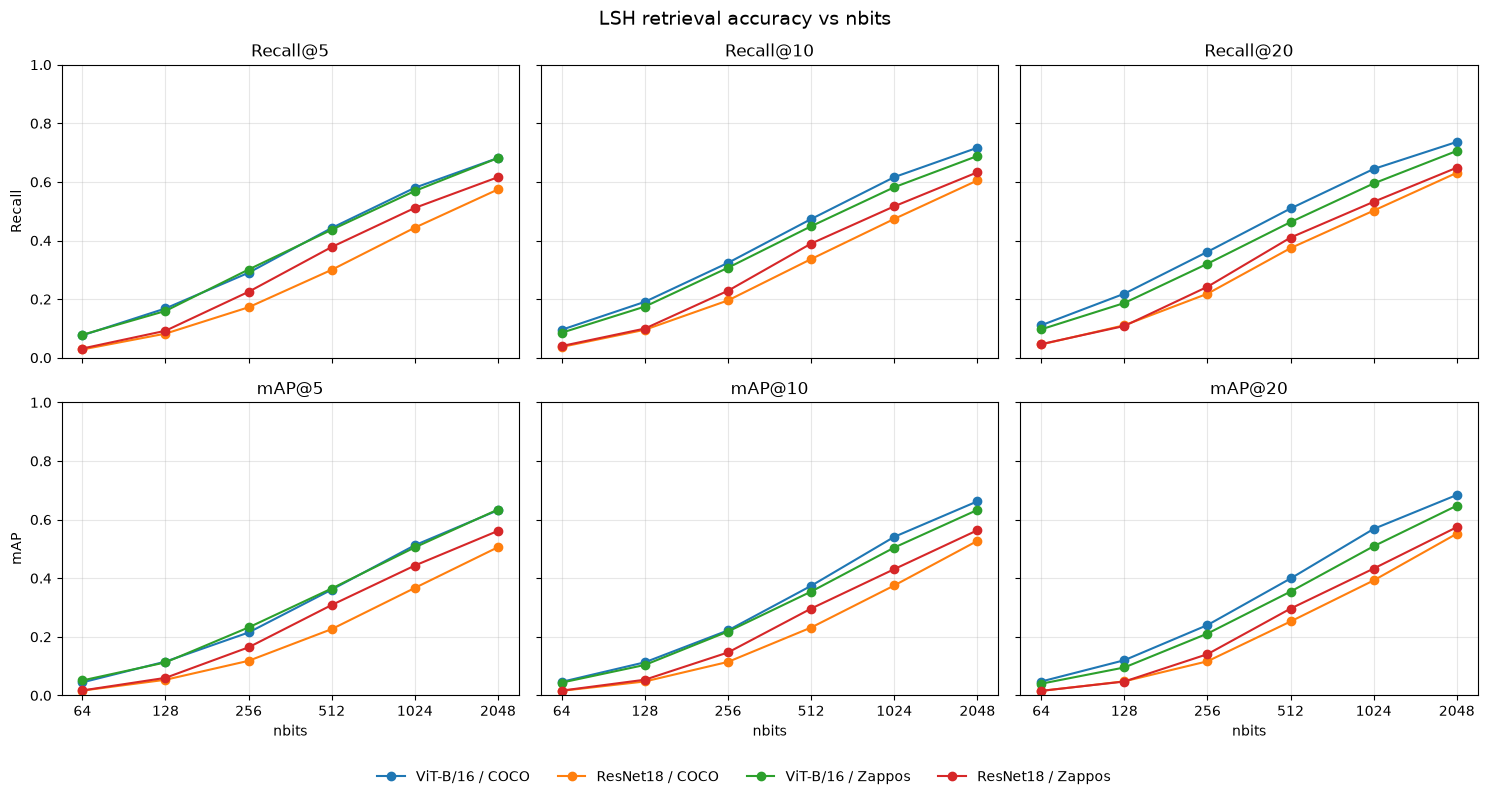

In [5]:
accuracy_figures("LSH", "lsh")

### LSH: speed

Latency rises roughly in proportion to `nbits` from 256 bits up. At
`nbits = 2048` LSH is slower than exact search in every experiment (and
already at 1024 for ResNet18), so the accuracy gained at the top of the
sweep costs the whole speed advantage.

saved media/lsh_latency.png


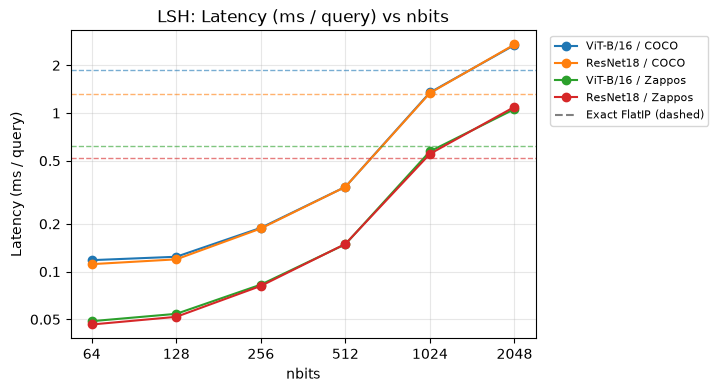

In [6]:
cost_figure("LSH", "lsh", "latency")

### LSH: memory

The index stores `nbits` bits per vector, so its size doubles with every
step. LSH is the only method whose index size depends on its parameter. Even
at 2048 bits the index is 6-10x smaller than the full vectors.

saved media/lsh_index_size.png


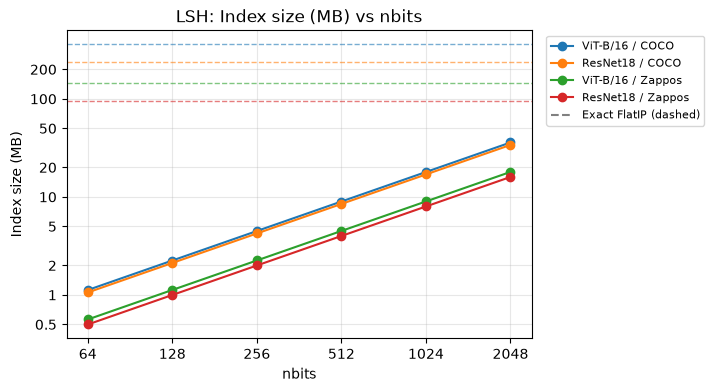

In [7]:
cost_figure("LSH", "lsh", "index_size")

## IVF-Flat (nprobe)

IVF splits the gallery into `nlist = 256` clusters (k-means on the
embeddings). A query is compared only against the vectors in its
`nprobe` nearest clusters, so a larger `nprobe` searches more of the
gallery: higher accuracy, slower search. At `nprobe = 256` it would be
exact search.

### IVF-Flat: accuracy

IVF-Flat stores the full, uncompressed vectors, so any miss comes from a
true neighbour sitting in a cluster that was not probed. For the same reason
mAP@K equals Recall@K exactly: every true neighbour that is found is ranked
above every wrong result.

saved media/ivfflat_recall_at_5.png
saved media/ivfflat_recall_at_10.png


saved media/ivfflat_recall_at_20.png
saved media/ivfflat_map_at_5.png


saved media/ivfflat_map_at_10.png
saved media/ivfflat_map_at_20.png


saved media/ivfflat_accuracy_grid.png


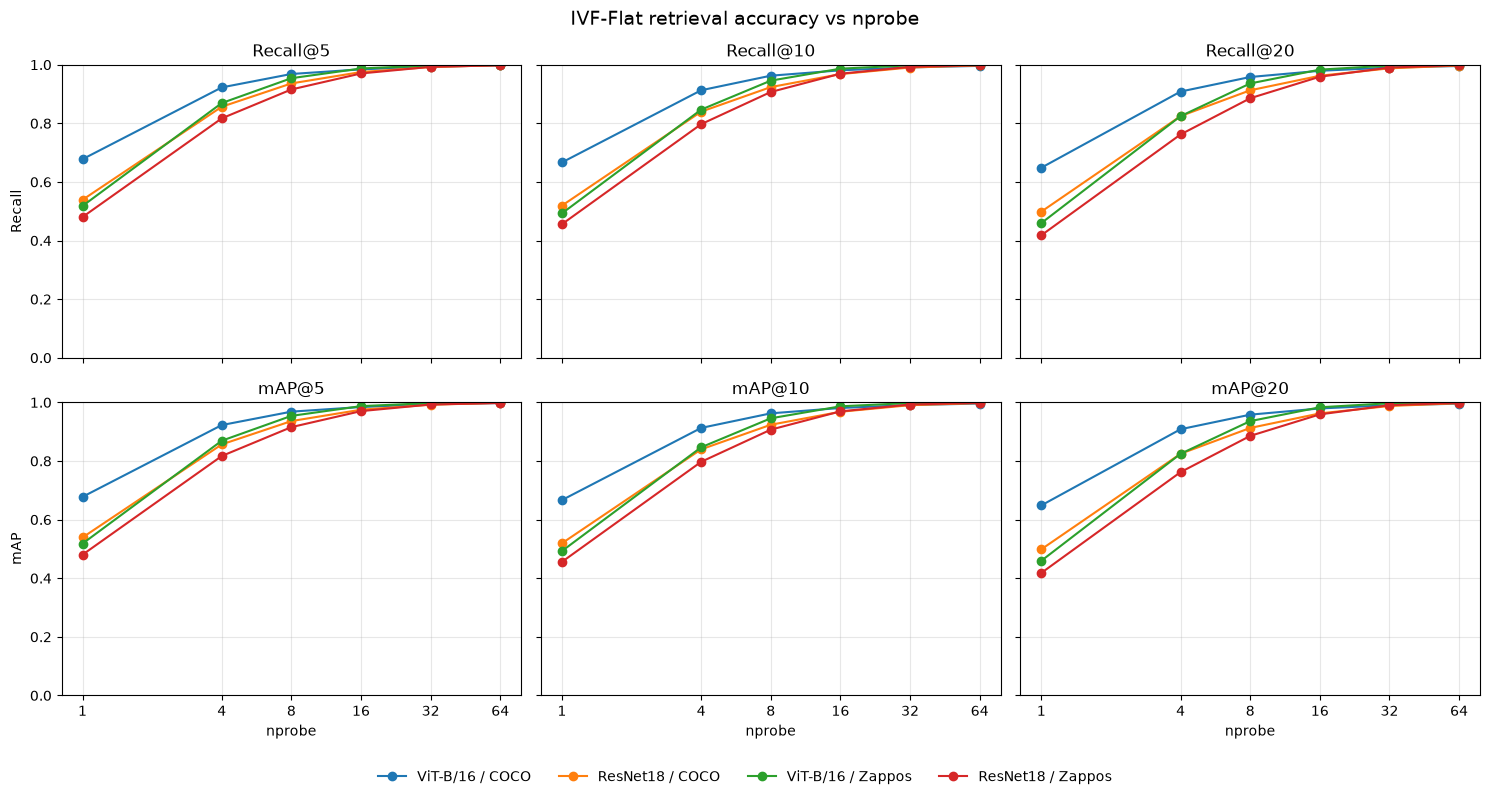

In [8]:
accuracy_figures("IVF-Flat", "ivfflat")

### IVF-Flat: speed

Latency grows about linearly with `nprobe`, since each extra cluster adds
its vectors to the scan. At `nprobe = 64` (a quarter of the gallery) IVF-Flat
is slower than exact search in every experiment: the brute-force scan is a
single well-optimised matrix product, which beats probing many small lists.

saved media/ivfflat_latency.png


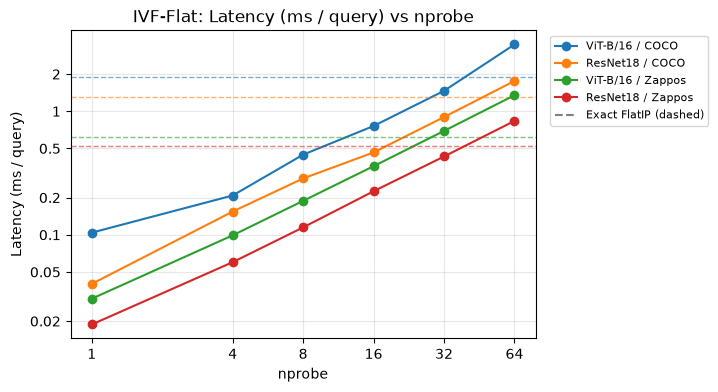

In [9]:
cost_figure("IVF-Flat", "ivfflat", "latency")

### IVF-Flat: memory

`nprobe` is a search-time setting, so the index size is the same at every
value: the full vectors plus 256 centroids, just above exact search.

saved media/ivfflat_index_size.png


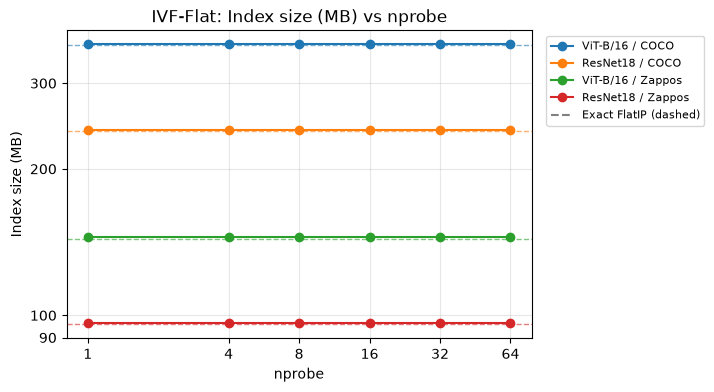

In [10]:
cost_figure("IVF-Flat", "ivfflat", "index_size")

## IVF-PQ (nprobe)

Same clustering and `nprobe` as IVF-Flat, but each vector is compressed
with product quantization: split into `m` sub-vectors (48 for ViT, 32 for
ResNet18), each stored as one 8-bit code.

### IVF-PQ: accuracy

Distances are approximate, so accuracy levels off below IVF-Flat even when
many clusters are probed; the gap between the two sets of charts is the cost
of compression.

saved media/ivfpq_recall_at_5.png
saved media/ivfpq_recall_at_10.png


saved media/ivfpq_recall_at_20.png
saved media/ivfpq_map_at_5.png


saved media/ivfpq_map_at_10.png
saved media/ivfpq_map_at_20.png


saved media/ivfpq_accuracy_grid.png


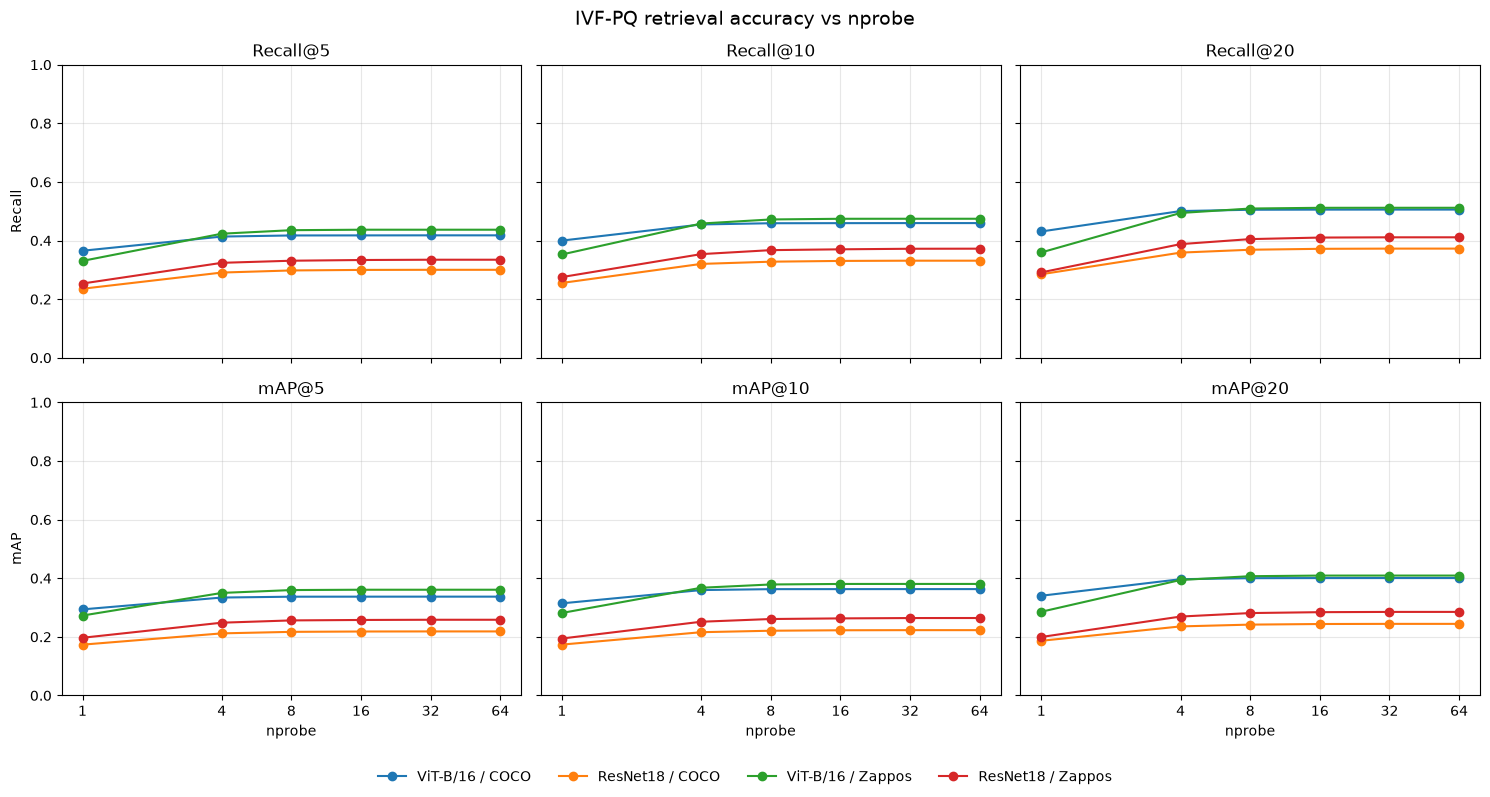

In [11]:
accuracy_figures("IVF-PQ", "ivfpq")

### IVF-PQ: speed

Latency also grows with `nprobe`, but more slowly than IVF-Flat, because
each probed vector is a short PQ code instead of a full vector.

saved media/ivfpq_latency.png


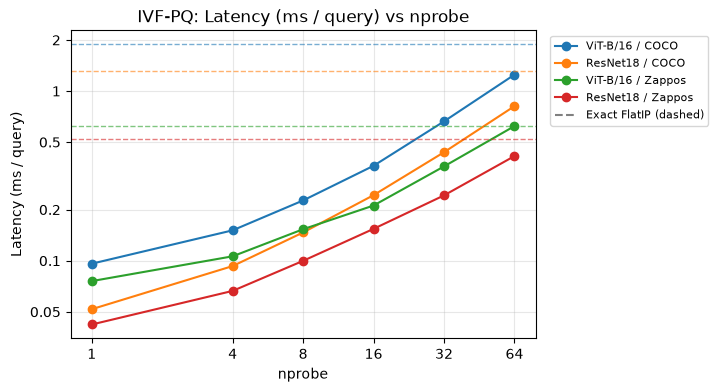

In [12]:
cost_figure("IVF-PQ", "ivfpq", "latency")

### IVF-PQ: memory

The index is about 2-3% of the size of exact search (48 or 32 bytes per
vector instead of 3 KB or 2 KB), and like IVF-Flat it does not change with
`nprobe`.

saved media/ivfpq_index_size.png


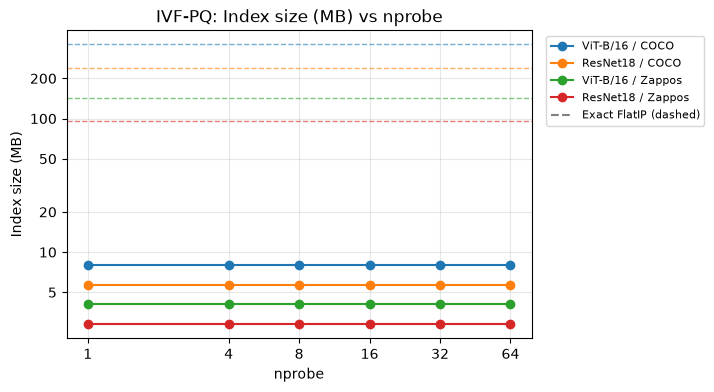

In [13]:
cost_figure("IVF-PQ", "ivfpq", "index_size")

## HNSW (efSearch)

HNSW links the gallery vectors into a layered nearest-neighbour graph
(`M = 32` links per node, built with `efConstruction = 200`) and answers a
query by walking that graph towards it. `efSearch` is the size of the
candidate list kept during the walk: a larger list explores more of the
graph, so accuracy rises and search gets slower.

### HNSW: accuracy

Vectors are stored uncompressed, so distances are exact and mAP@K equals
Recall@K. Every value is above 0.85, so the score axis is **zoomed to
0.84-1.0** (the other charts use 0-1) to make the differences between
experiments visible.

saved media/hnsw_recall_at_5.png


saved media/hnsw_recall_at_10.png


saved media/hnsw_recall_at_20.png


saved media/hnsw_map_at_5.png
saved media/hnsw_map_at_10.png


saved media/hnsw_map_at_20.png


saved media/hnsw_accuracy_grid.png


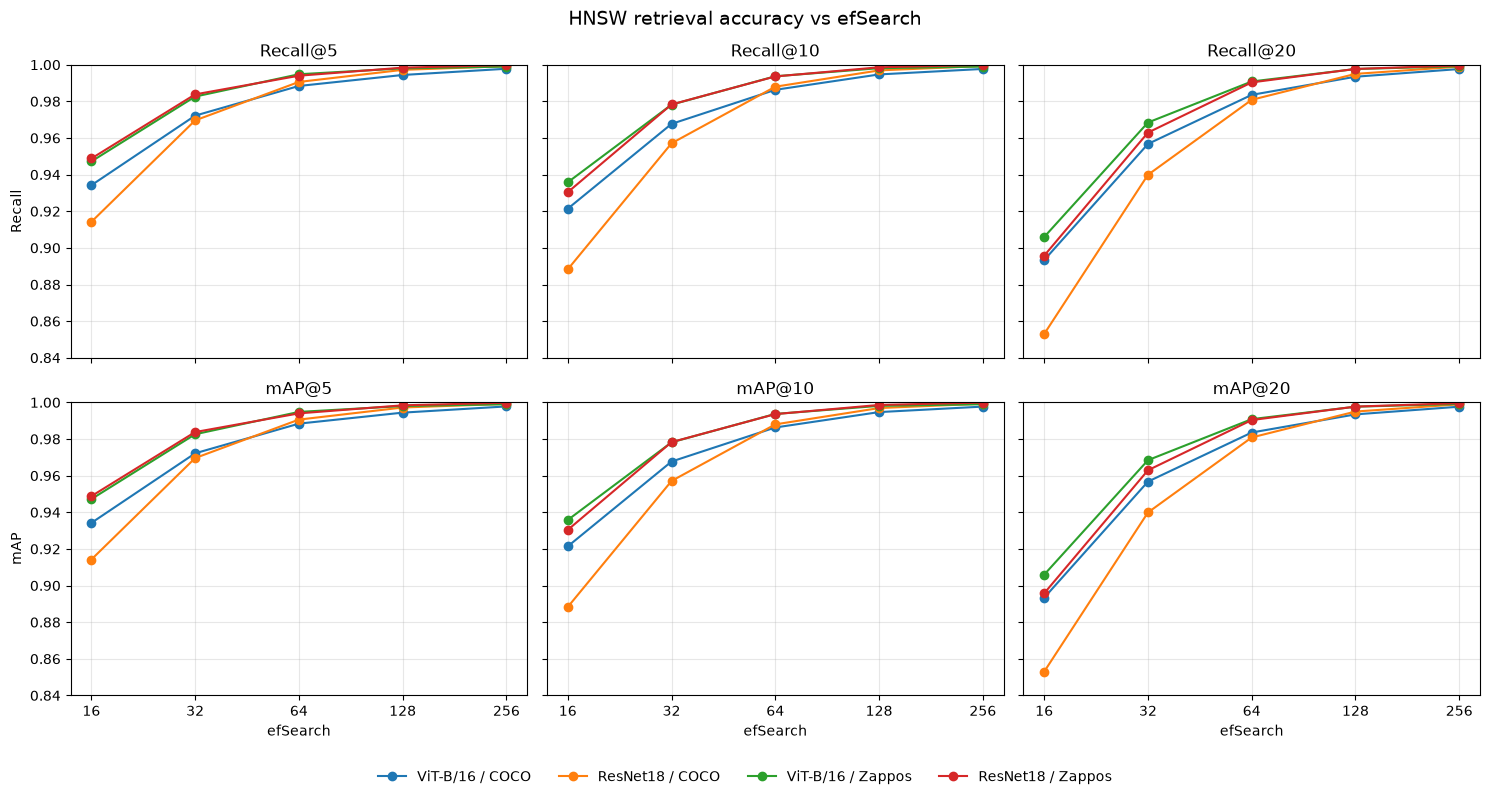

In [14]:
accuracy_figures("HNSW", "hnsw", ylim=(0.84, 1.0))

### HNSW: speed

Latency grows with `efSearch`, since a longer candidate list means more of
the graph is visited. On COCO HNSW stays faster than exact search across the
whole sweep, but on the smaller Zappos gallery exact search is already fast
and HNSW at `efSearch = 256` is slower.

saved media/hnsw_latency.png


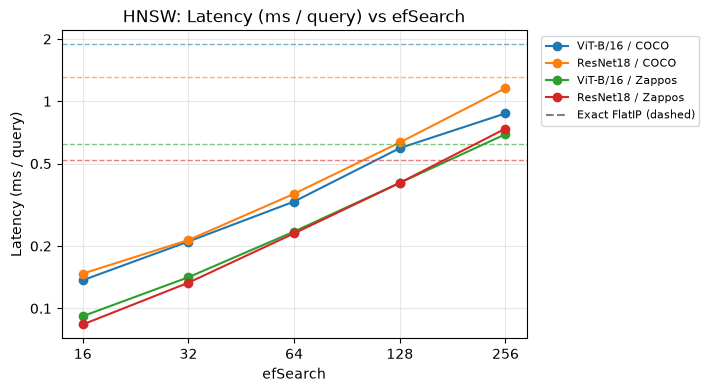

In [15]:
cost_figure("HNSW", "hnsw", "latency")

### HNSW: memory

The index holds the full vectors plus 32 graph links per node, so it is
about 9-13% larger than exact search, and the same at every `efSearch`.

saved media/hnsw_index_size.png


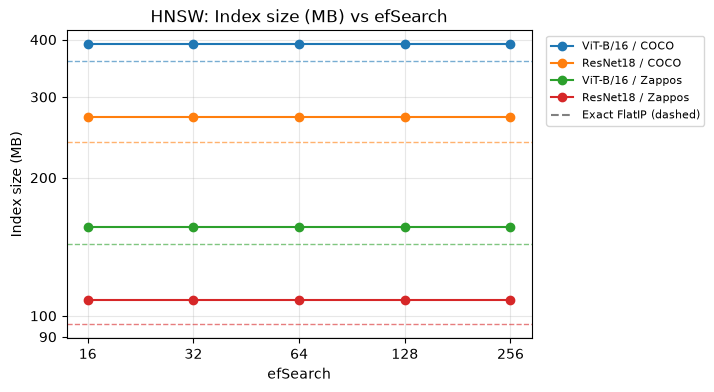

In [16]:
cost_figure("HNSW", "hnsw", "index_size")

## HNSW-PQ (efSearch)

Same graph and `efSearch` as HNSW, but the graph walk uses product-quantized
vectors (`m` = 48 sub-vectors for ViT, 32 for ResNet18, 8 bits each).

### HNSW-PQ: accuracy

The walk is guided by approximate distances, so it can step towards the
wrong nodes, and accuracy stays well below plain HNSW.

saved media/hnswpq_recall_at_5.png


saved media/hnswpq_recall_at_10.png


saved media/hnswpq_recall_at_20.png
saved media/hnswpq_map_at_5.png


saved media/hnswpq_map_at_10.png
saved media/hnswpq_map_at_20.png


saved media/hnswpq_accuracy_grid.png


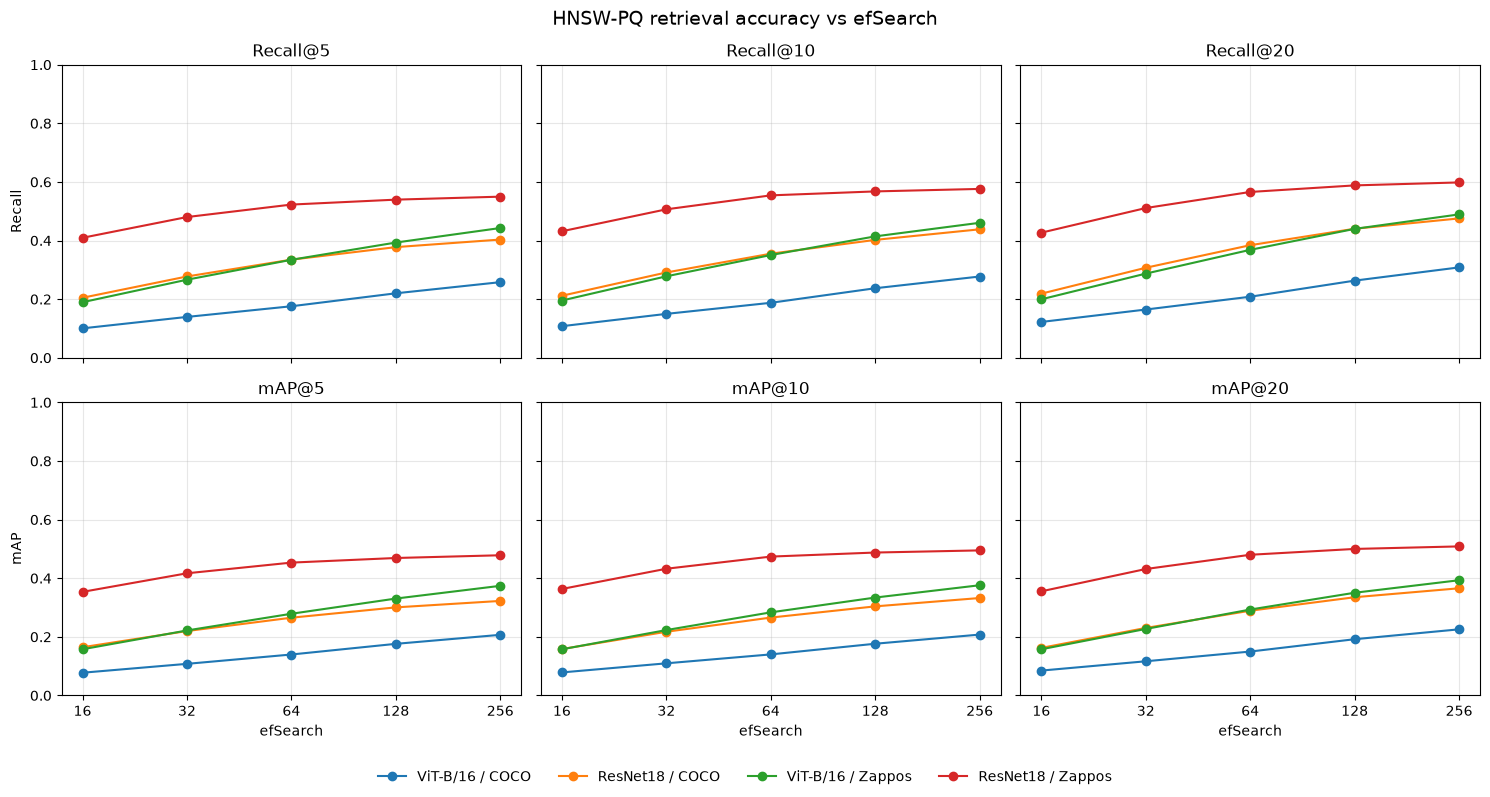

In [17]:
accuracy_figures("HNSW-PQ", "hnswpq")

### HNSW-PQ: speed

The same graph walk over PQ codes is faster than plain HNSW at every
`efSearch`, because each distance is computed from a short code.

saved media/hnswpq_latency.png


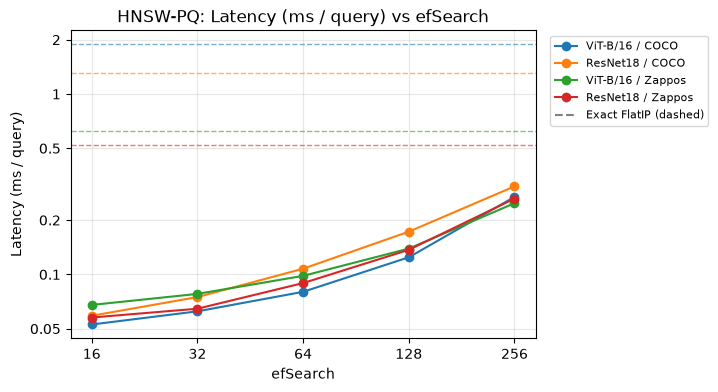

In [18]:
cost_figure("HNSW-PQ", "hnswpq", "latency")

### HNSW-PQ: memory

The index is about 10-15% of the size of exact search: the vectors shrink to
48 or 32 bytes, but the 32 graph links per node stay, and they now take most
of the space. As with HNSW, the size does not depend on `efSearch`.

saved media/hnswpq_index_size.png


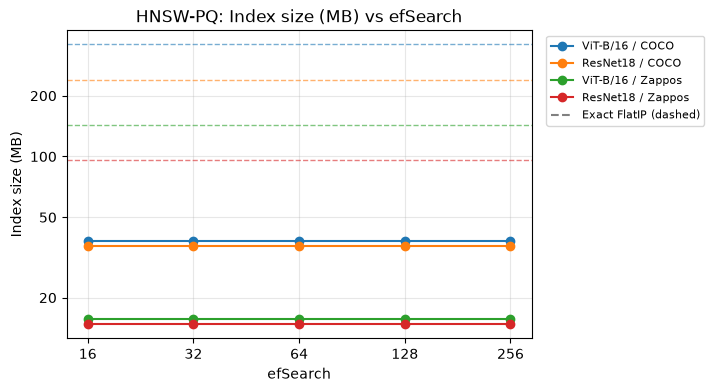

In [19]:
cost_figure("HNSW-PQ", "hnswpq", "index_size")

## Choosing the best setting

Two separate scoring functions (in `scoring.py`) give every setting a score,
and the highest score is the pick. Picks are shown per experiment and overall
(the setting with the highest mean score over the four experiments).

- **Weighted score**: `(w_acc * accuracy + w_speed * speed + w_mem * memory)`,
  with equal weights (1/3 each) for now. The accuracy weight is split equally
  over the six accuracy metrics (Recall and mAP at 5, 10 and 20), so accuracy is
  their mean. Speed and memory are `log(ratio vs exact search) / log(100)`,
  clipped to [-1, 1]: a setting as fast (or as large) as exact search scores 0,
  one 100x faster (or smaller) scores 1, and one slower than exact search
  scores below 0.
- **Knee score**: within each sweep, latency (log scale) and Recall@10 are both
  scaled to 0-1 and the score is `recall - latency`. Its maximum is the point of
  diminishing returns: after it, each doubling of latency buys less recall.
  This score uses speed and accuracy only.

Memory only changes which setting wins for LSH. For the other methods `nprobe` and
`efSearch` are search-time settings, so the index size is the same at every value.
Memory still matters when comparing weighted scores *between* methods.

In [20]:
from scoring import ACC_METRIC, WEIGHTS, best_overall, best_per_config, knee_score, weighted_score

SCORES = {"weighted": "Weighted score", "knee": "Knee score"}

# Every swept setting (Exact FlatIP has no parameter) with both scores.
scored = results[results["param_name"].notna()].copy()
scored["weighted"] = weighted_score(scored, WEIGHTS)
scored["knee"] = knee_score(scored)

# Best setting of each method in each experiment, one table per score.
for score, title in SCORES.items():
    picks = (best_per_config(scored, score)
             .pivot(index="algorithm", columns="config", values="param_value")
             .reindex(index=[m for m in METHOD_ORDER if m in SWEEP_PARAM], columns=meta.index)
             .rename(columns=meta["label"]).astype(int))
    picks.insert(0, "parameter", picks.index.map(SWEEP_PARAM))
    print(f"{title}: best setting per experiment")
    display(picks)

# One setting per method: highest mean score over the four experiments.
overall = []
for score, title in SCORES.items():
    best = best_overall(scored, score).set_index("algorithm")
    overall.append(best.drop(columns=score).rename(columns=lambda c: f"{score}: {c}"))
overall = (pd.concat(overall, axis=1)
           .reindex([m for m in METHOD_ORDER if m in SWEEP_PARAM]))
overall.insert(0, "parameter", overall.index.map(SWEEP_PARAM))
print(f"Best setting per method (mean over experiments; {ACC_METRIC} shown for reference)")
display(overall.round(3))

Weighted score: best setting per experiment


config,parameter,ViT-B/16 / COCO,ResNet18 / COCO,ViT-B/16 / Zappos,ResNet18 / Zappos
algorithm,,,,,
LSH,nbits,128,128,128,128
IVF-Flat,nprobe,4,4,4,4
IVF-PQ,nprobe,1,1,4,1
HNSW,efSearch,16,16,16,16
HNSW-PQ,efSearch,16,32,64,32


Knee score: best setting per experiment


config,parameter,ViT-B/16 / COCO,ResNet18 / COCO,ViT-B/16 / Zappos,ResNet18 / Zappos
algorithm,,,,,
LSH,nbits,512,512,512,512
IVF-Flat,nprobe,4,8,8,8
IVF-PQ,nprobe,4,4,4,4
HNSW,efSearch,64,64,32,32
HNSW-PQ,efSearch,128,64,64,64


Best setting per method (mean over experiments; recall_at_10 shown for reference)


,parameter,weighted: param_value,weighted: recall_at_10,weighted: speedup,weighted: compression,knee: param_value,knee: recall_at_10,knee: speedup,knee: compression
algorithm,,,,,,,,,
LSH,nbits,128.0,0.140,11.910,124.146,512.0,0.412,4.247,31.038
IVF-Flat,nprobe,4.0,0.849,8.125,0.993,8.0,0.935,4.163,0.993
IVF-PQ,nprobe,1.0,0.321,16.362,38.739,4.0,0.397,10.058,38.739
HNSW,efSearch,16.0,0.919,8.917,0.901,32.0,0.970,5.846,0.901
HNSW-PQ,efSearch,32.0,0.306,15.913,7.920,64.0,0.362,11.952,7.920


The two scores answer different questions. With equal weights, the
**weighted score** favours the cheapest settings (HNSW `efSearch = 16`,
IVF-Flat `nprobe = 4`, IVF-PQ `nprobe = 1`, LSH `nbits = 128`): a step up the
sweep adds less to the accuracy term than it takes from the speed term. LSH
and IVF-PQ get the highest weighted scores of all the methods because of their
large compression, even though their recall is low. The **knee score** sits one or two
steps higher on every method (HNSW `efSearch = 32`, IVF-Flat `nprobe = 8`,
IVF-PQ `nprobe = 4`, LSH `nbits = 512`), where recall has mostly levelled off.
The picks are the same in all four experiments except for a one-step shift here and there,
so the overall choice is stable across model and dataset.

## Effect of PQ compression

`pq_sweep.py` rebuilds IVF-PQ and HNSW-PQ and varies only the PQ code size
`m`: the number of sub-quantizers, each storing one 8-bit code, so a vector
takes `m` bytes (full vectors take 3,072 bytes for ViT-B/16 and 2,048 for
ResNet18). At the same `m` both models get the **same memory per vector**;
each sub-quantizer then covers `dimension / m` dimensions. The main benchmark
uses `m = 48` (ViT-B/16) and `m = 32` (ResNet18). The sweep reuses the main
benchmark's queries, gallery and exact top-K, so the numbers are directly
comparable.

The search setting is **fixed per experiment** at the knee-score pick of the
full-vector partner, so each PQ method is compared with its full-vector
version at the same setting:

| Experiment | IVF `nprobe` | HNSW `efSearch` |
|---|---|---|
| ViT-B/16 / COCO | 4 | 64 |
| ResNet18 / COCO | 8 | 64 |
| ViT-B/16 / Zappos | 8 | 32 |
| ResNet18 / Zappos | 8 | 32 |

The charts below follow the method sections (accuracy, speed, memory, build
time), with `m` on the x-axis. Each **dashed line is the full-vector partner**
(IVF-Flat or HNSW at the same setting, i.e. "no PQ") in the experiment of the
same colour. Because the setting (and the gallery size) differs between
experiments, read each line against its own dashed line rather than
comparing lines directly.


In [21]:
# PQ sweep results from pq_sweep.py. Each configuration fixes nprobe / efSearch
# at its own knee pick of IVF-Flat / HNSW and varies m.
PQ_PAIRS = {"IVF-PQ": "IVF-Flat", "HNSW-PQ": "HNSW"}   # PQ method -> full-vector partner
PQ_COLUMNS = {"recall_at_10": "Recall@10", "map_at_10": "mAP@10",
              "latency_ms_per_query": "Latency (ms)", "compression": "Compression (x)"}

pq_rows = []
for key in meta.index:
    path = results_dir(key) / "pq_sweep" / "pq_sweep_results.json"
    if not path.exists():
        print(f"{key}: no pq_sweep_results.json - run pq_sweep.py --config {key}")
        continue
    for r in json.loads(path.read_text())["results"]:
        pq_rows.append({
            "config": key,
            "algorithm": r["algorithm"],
            # m is the swept parameter here; the fixed search setting is kept aside.
            "param_name": "m",
            "param_value": r["parameters"]["m"],
            "search_value": r["parameters"][SWEEP_PARAM[r["algorithm"]]],
            **{k: v for k, v in r.items() if k not in ("algorithm", "parameters")},
        })

# pq: one row per (config, PQ method, m). pq_reference[method]: its
# full-vector partner at the same search setting, indexed by config ("no PQ").
pq, pq_reference = None, {}
if pq_rows:
    pq = pd.DataFrame(pq_rows)
    pq["compression"] = pq["config"].map(exact["index_size_mb"]) / pq["index_size_mb"]
    for pq_algo, flat_algo in PQ_PAIRS.items():
        sweep = pick(pq_algo, data=pq).sort_values("param_value")
        fixed = (sweep[["config", "search_value"]].drop_duplicates()
                 .rename(columns={"search_value": "param_value"}))
        pq_reference[pq_algo] = (pick(flat_algo).merge(fixed, on=["config", "param_value"])
                                 .set_index("config"))
        rows = pd.concat([pq_reference[pq_algo].reset_index().assign(pq="no PQ"),
                          sweep.assign(pq="m = " + sweep["param_value"].astype(str))])
        table = (rows.pivot(index="pq", columns="config", values=list(PQ_COLUMNS))
                 .reindex(rows["pq"].unique())
                 .reindex(columns=[c for c in meta.index if c in fixed["config"].values], level=1)
                 .rename(columns=PQ_COLUMNS, level=0)
                 .rename(columns=meta["label"], level=1))
        table.index.name = None
        setting = ", ".join(f"{meta.loc[c, 'label']}: {v:g}" for c, v in fixed.itertuples(index=False))
        print(f"{pq_algo} vs {flat_algo} at {SWEEP_PARAM[flat_algo]} = ({setting})")
        display(table.round(3))

IVF-PQ vs IVF-Flat at nprobe = (ViT-B/16 / COCO: 4, ResNet18 / COCO: 8, ResNet18 / Zappos: 8, ViT-B/16 / Zappos: 8)


Recall@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.913           0.924             0.946             0.907   
m = 8             0.084           0.149             0.179             0.185   
m = 16            0.156           0.223             0.263             0.264   
m = 32            0.345           0.328             0.392             0.367   
m = 64            0.531           0.502             0.536             0.530   
m = 128           0.692           0.689             0.707             0.712   

                 mAP@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.913           0.924             0.946             0.907   
m = 8             0.039           0.076             0.096             0.101   
m = 16            0.083           0.129             0.165             0.162   
m = 32            0.246           0.221             0.287             0.261   
m = 64            0.443           0.399             0.450             0.445   
m = 128           0.645           0.635             0.660             0.668   

           Latency (ms)                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.208           0.286             0.188             0.115   
m = 8             0.034           0.053             0.044             0.039   
m = 16            0.060           0.078             0.057             0.054   
m = 32            0.102           0.146             0.075             0.063   
m = 64            0.188           0.212             0.140             0.118   
m = 128           0.365           0.541             0.362             0.239   

        Compression (x)                                                      
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos  
no PQ             0.995           0.994             0.992             0.991  
m = 8           106.415          83.304            63.829            54.710  
m = 16           83.324          62.851            54.732            45.076  
m = 32           58.107          42.153            42.591            33.337  
m = 64           36.197          25.414            29.502            21.919  
m = 128          20.636          14.165            18.272            13.009

HNSW-PQ vs HNSW at efSearch = (ViT-B/16 / COCO: 64, ResNet18 / COCO: 64, ResNet18 / Zappos: 32, ViT-B/16 / Zappos: 32)


Recall@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.986           0.988             0.978             0.978   
m = 8             0.052           0.077             0.080             0.107   
m = 16            0.092           0.129             0.125             0.185   
m = 32            0.156           0.355             0.178             0.507   
m = 64            0.311           0.624             0.436             0.714   
m = 128           0.721           0.782             0.750             0.843   

                 mAP@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.986           0.988             0.978             0.978   
m = 8             0.024           0.041             0.040             0.064   
m = 16            0.050           0.081             0.077             0.130   
m = 32            0.105           0.266             0.130             0.432   
m = 64            0.251           0.547             0.372             0.667   
m = 128           0.678           0.749             0.710             0.825   

           Latency (ms)                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.328           0.358             0.141             0.133   
m = 8             0.040           0.061             0.037             0.033   
m = 16            0.068           0.065             0.035             0.029   
m = 32            0.086           0.080             0.043             0.044   
m = 64            0.140           0.166             0.112             0.089   
m = 128           0.274           0.408             0.222             0.176   

        Compression (x)                                                      
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos  
no PQ             0.919           0.883             0.919             0.883  
m = 8            10.717           7.199            10.369             7.039  
m = 16           10.426           7.002            10.096             6.851  
m = 32            9.889           6.639             9.592             6.503  
m = 64            8.966           6.015             8.720             5.903  
m = 128           7.555           5.063             7.380             4.984

### IVF-PQ vs m: accuracy

More sub-quantizers mean a finer code per vector, so accuracy rises with `m`
towards IVF-Flat (dashed).

saved media/pqsweep_ivfpq_recall_at_5.png


saved media/pqsweep_ivfpq_recall_at_10.png
saved media/pqsweep_ivfpq_recall_at_20.png


saved media/pqsweep_ivfpq_map_at_5.png
saved media/pqsweep_ivfpq_map_at_10.png


saved media/pqsweep_ivfpq_map_at_20.png


saved media/pqsweep_ivfpq_accuracy_grid.png


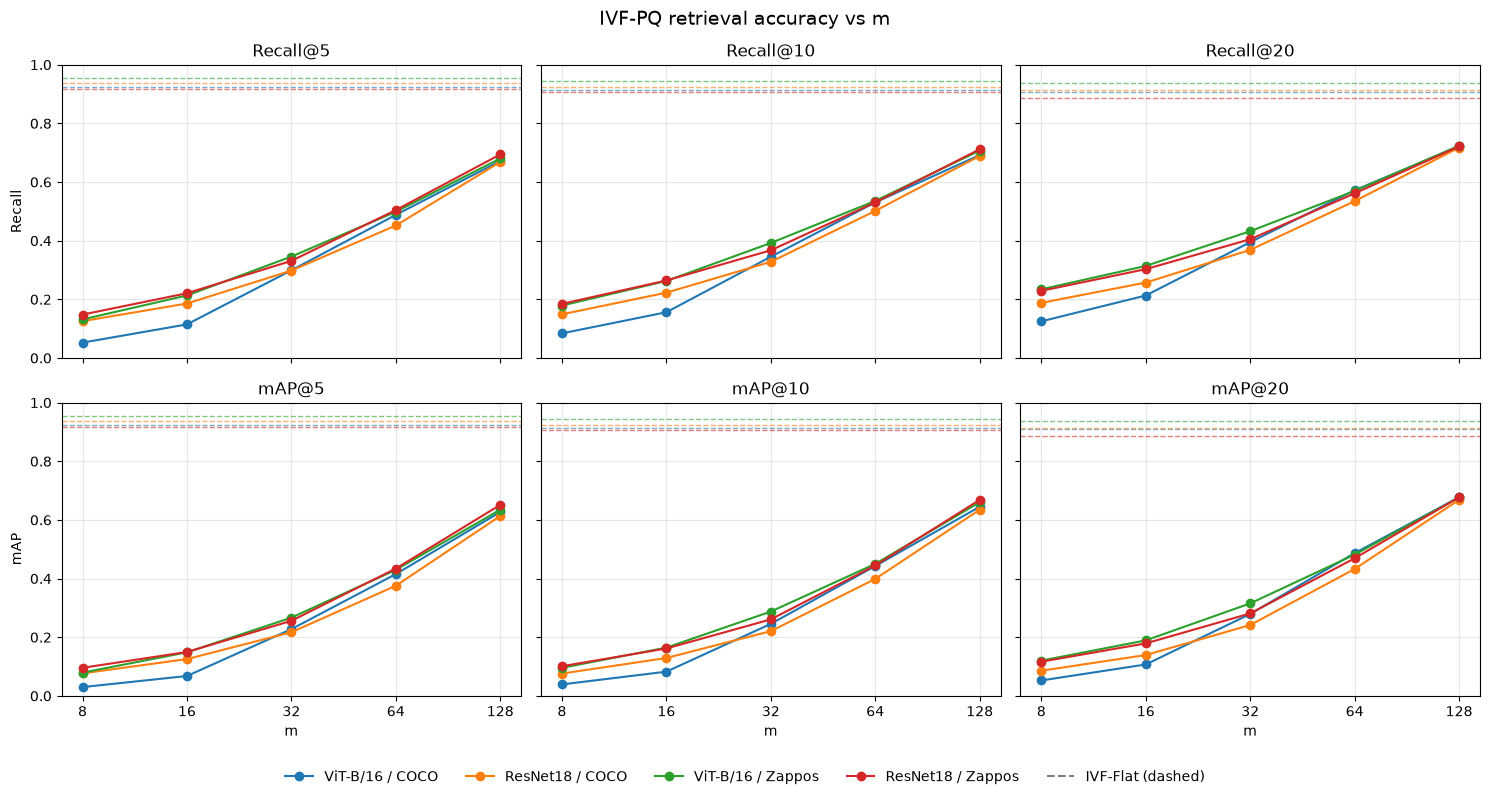

In [22]:
if pq is not None:
    accuracy_figures("IVF-PQ", "pqsweep_ivfpq", data=pq, reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### IVF-PQ vs m: speed

Each candidate's distance is a sum of `m` table lookups, so latency grows
with `m`. The dashed IVF-Flat latency comes from the main benchmark run, so
small timing differences between the two runs are expected.

saved media/pqsweep_ivfpq_latency.png


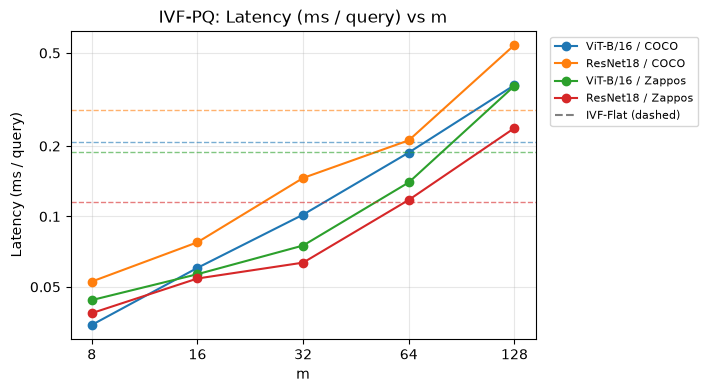

In [23]:
if pq is not None:
    cost_figure("IVF-PQ", "pqsweep_ivfpq", "latency", data=pq, reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### IVF-PQ vs m: memory

The PQ codes take `m` bytes per vector, so the index grows with `m`.

saved media/pqsweep_ivfpq_index_size.png


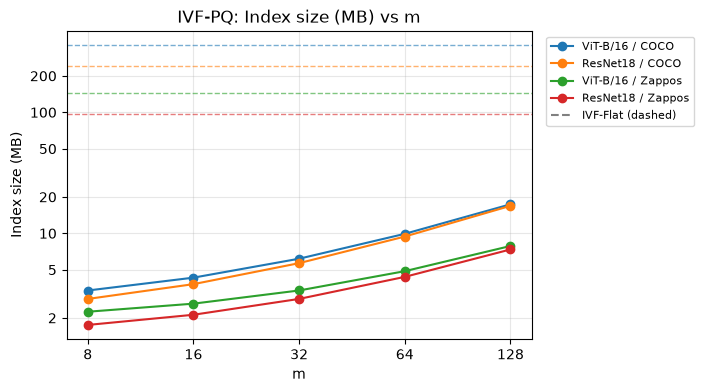

In [24]:
if pq is not None:
    cost_figure("IVF-PQ", "pqsweep_ivfpq", "index_size", data=pq, reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### IVF-PQ vs m: build time

Building the index means training k-means for the PQ codebooks on the gallery sample (one
256-centroid codebook per sub-quantizer, so `m` of them) and encoding the
gallery. Builds use every CPU core, unlike the single-threaded search
timings. The dashed line is IVF-Flat's build time from the main benchmark run.

saved media/pqsweep_ivfpq_build_time.png


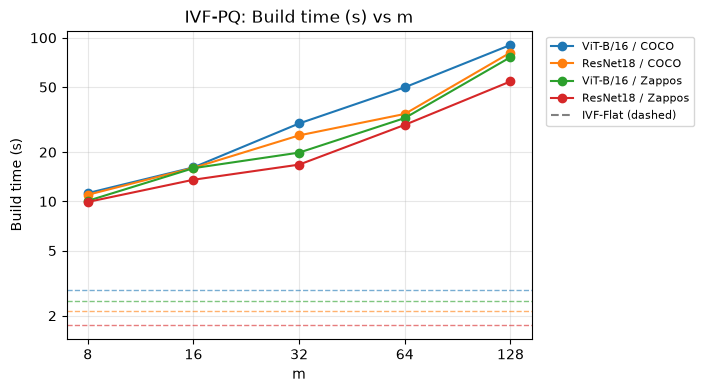

In [25]:
if pq is not None:
    cost_figure("IVF-PQ", "pqsweep_ivfpq", "build_time", data=pq,
                reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### HNSW-PQ vs m: accuracy

More sub-quantizers mean a finer code per vector, so accuracy rises with `m`
towards HNSW (dashed).

saved media/pqsweep_hnswpq_recall_at_5.png
saved media/pqsweep_hnswpq_recall_at_10.png


saved media/pqsweep_hnswpq_recall_at_20.png
saved media/pqsweep_hnswpq_map_at_5.png


saved media/pqsweep_hnswpq_map_at_10.png
saved media/pqsweep_hnswpq_map_at_20.png


saved media/pqsweep_hnswpq_accuracy_grid.png


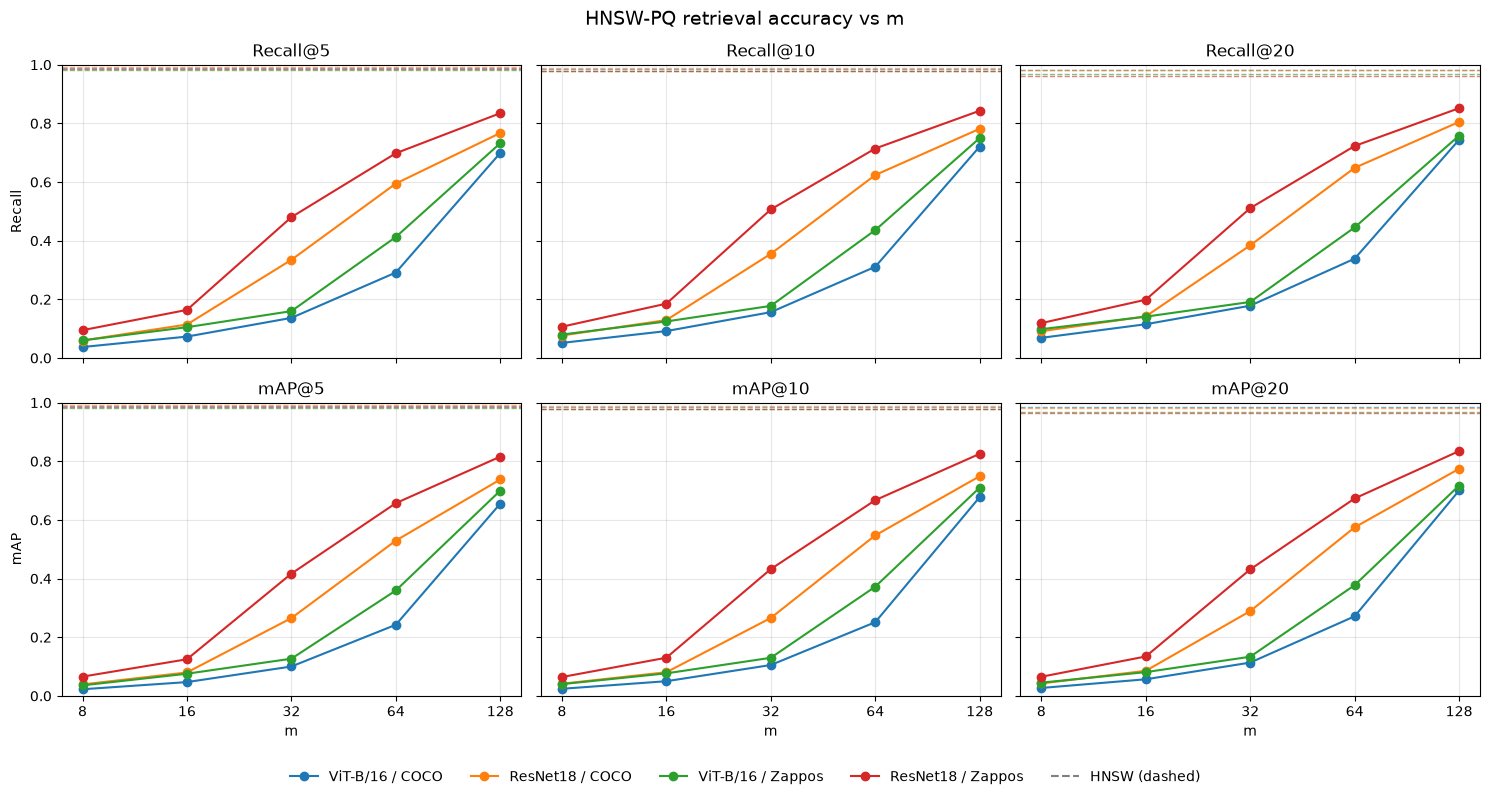

In [26]:
if pq is not None:
    accuracy_figures("HNSW-PQ", "pqsweep_hnswpq", data=pq, reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

### HNSW-PQ vs m: speed

Each candidate's distance is a sum of `m` table lookups, so latency grows
with `m`. The dashed HNSW latency comes from the main benchmark run, so
small timing differences between the two runs are expected.

saved media/pqsweep_hnswpq_latency.png


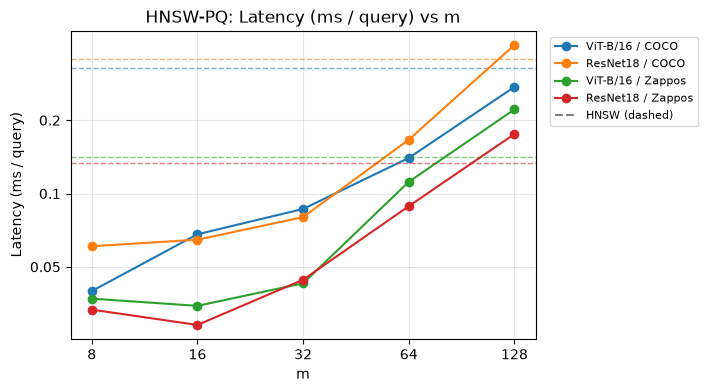

In [27]:
if pq is not None:
    cost_figure("HNSW-PQ", "pqsweep_hnswpq", "latency", data=pq, reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

### HNSW-PQ vs m: memory

The PQ codes take `m` bytes per vector, so the index grows with `m`.
 HNSW-PQ also stores 32 graph links per node, which do not depend on `m`.

saved media/pqsweep_hnswpq_index_size.png


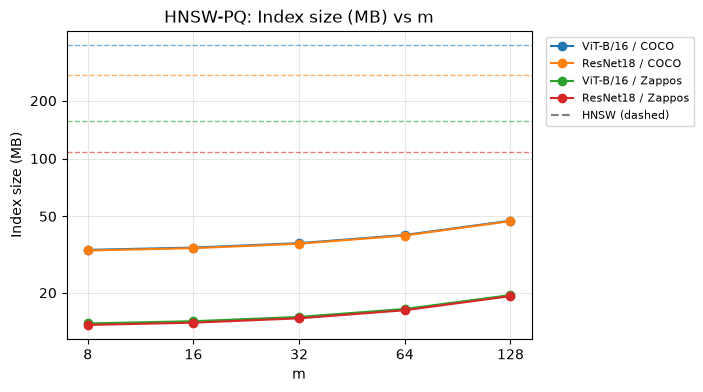

In [28]:
if pq is not None:
    cost_figure("HNSW-PQ", "pqsweep_hnswpq", "index_size", data=pq, reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

### HNSW-PQ vs m: build time

Building the index means training the PQ codebooks plus the graph construction on the gallery sample (one
256-centroid codebook per sub-quantizer, so `m` of them) and encoding the
gallery. Builds use every CPU core, unlike the single-threaded search
timings. The dashed line is HNSW's build time from the main benchmark run.

saved media/pqsweep_hnswpq_build_time.png


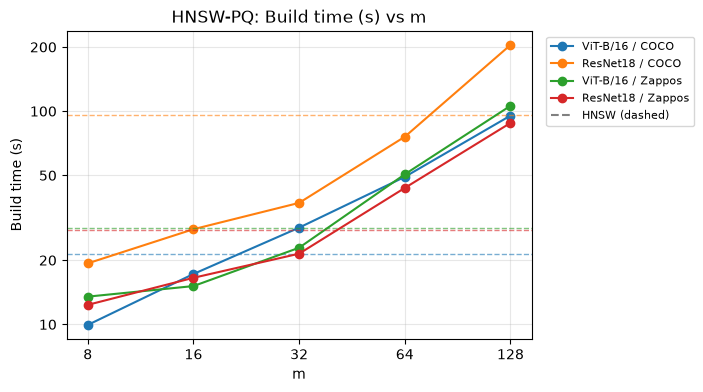

In [29]:
if pq is not None:
    cost_figure("HNSW-PQ", "pqsweep_hnswpq", "build_time", data=pq,
                reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

## Corruption robustness

How much does corrupting the **query** change retrieval? The gallery stays
clean; only the query image is perturbed (rotation, crop, brightness, blur,
saturation, hue) - 200 of the benchmark's held-out queries x 34 variants
each. The same sweep is measured with exact search (the baseline,
`pipeline/corruption.py`) and with the ANN indexes rebuilt at their benchmark
knee settings (IVF-Flat and HNSW, `pipeline/index_robustness.py`):

| Name | Comparison | Question |
|---|---|---|
| **Embedding drift** | cosine(clean, corrupted) | Did the query embedding move? |
| **Exact-search Recall@10** | corrupted Exact vs clean Exact | How many original neighbours survive corruption? |
| **Fidelity** | corrupted ANN vs corrupted Exact | Is the ANN index still accurate for the corrupted query? |
| **End-to-End** | corrupted ANN vs clean Exact | Does the complete system preserve the original result? |
| **Stability** | corrupted ANN vs clean ANN | Does the index keep returning the same results? |

- **Mean Recall@10** is the average fraction of the 10 reference neighbours
  retained across the 200 queries at one corruption type and level: `0.8`
  means an average of 8 of the 10 original neighbours were still returned.
- **Embedding drift** is the old robustness metric: it moves long before the
  ranking does, so it is shown first - a drifted embedding can still
  retrieve the same neighbours.
- **Exact-search Recall@10** is the model-only baseline: the recall **kept**
  by exact search once the embedding changed - the unavoidable loss that no
  index choice can fix.
- **End-to-End** is what the user actually gets: the recall **kept** by the
  index on the same corrupted query; its gap to the exact-search recall is
  the extra loss the index itself adds (near zero in these results).
- The `original` level (the uncorrupted query) anchors the self-checks:
  exact-search recall ~ 1.0, Stability exactly 1.0, and Fidelity = End-to-End.

Skipped when `results/<config>/robustness/corruption_summary.csv` (the
baseline) or `results/<config>/index_robustness/index_robustness_summary.csv`
(the index view) is missing - run Steps 3b/3c in the README.

### Settings and original-level self-checks

The ANN index view rebuilds IVF-Flat and HNSW at their benchmark knee
settings and searches them with the same corrupted queries. On the
`original` level (the uncorrupted query): Stability is exactly 1.0 (the
index is compared with itself) and Fidelity equals End-to-End (both exact
references agree).

In [30]:
# The corruption sweep and its ANN index view: settings, shared loaders and
# original-level self-checks. Needs results/<config>/robustness/ from
# pipeline/corruption.py (loaded in the setup cell as `corruption`) and
# results/<config>/index_robustness/ from pipeline/index_robustness.py.
sys.path.insert(0, str(EXPERIMENT_DIR / "pipeline"))
from perturbations import TRANSFORMS

K_SHOW = 10   # K displayed in every corruption figure
# Full-vector indexes only: the Step 3c results also cover the PQ variants -
# add "IVF-PQ" / "HNSW-PQ" back to this list to show them.
IR_ALGORITHMS = ["IVF-Flat", "HNSW"]

IR_KEYS = [k for k in meta.index
           if (results_dir(k) / "index_robustness" / "index_robustness_summary.csv").exists()]

def level_key(transform, level):
    """(transform index, level index) in the sweep's own order."""
    if transform == "original":
        return (-1, 0)
    for t, spec in enumerate(TRANSFORMS):
        if spec["name"] == transform:
            for l, value in enumerate(spec["values"]):
                if float(level) == float(value):
                    return (t, l)
    return (len(TRANSFORMS), 0)

if not IR_KEYS:
    ir_summary = None
    print("Index view skipped: no index-robustness results. Run, from the repository root:")
    print("  python experiments/ann-comparison/pipeline/corruption.py --config all")
    print("  python experiments/ann-comparison/pipeline/index_robustness.py --config all")
else:
    ir_summary = pd.concat(
        [pd.read_csv(results_dir(k) / "index_robustness" / "index_robustness_summary.csv",
                     keep_default_na=False)
         for k in IR_KEYS], ignore_index=True)
    ir_summary["order"] = [level_key(t, l)
                           for t, l in zip(ir_summary["transform"], ir_summary["level"])]

    # Settings per configuration. The original-level self-checks are internal:
    # stability must be exactly 1.0 and fidelity must equal end-to-end.
    overview = []
    for k in IR_KEYS:
        rows = ir_summary[ir_summary["config"] == k]
        for algorithm in IR_ALGORITHMS:
            original = rows[(rows["algorithm"] == algorithm)
                            & (rows["transform"] == "original")].iloc[0]
            assert float(original[f"stability_recall_at_{K_SHOW}_mean"]) == 1.0, (k, algorithm)
            overview.append({
                "config": meta.loc[k, "label"],
                "algorithm": algorithm,
                "setting": original["setting"],
                "index MB": round(float(original["index_size_mb"]), 1),
                "ms/variant": original["latency_ms_per_variant"],
            })
    display(pd.DataFrame(overview))
    for k in IR_KEYS:
        original = ir_summary[(ir_summary["config"] == k) & (ir_summary["transform"] == "original")]
        gap = (original[f"fidelity_recall_at_{K_SHOW}_mean"]
               - original[f"end_to_end_recall_at_{K_SHOW}_mean"]).abs().max()
        print(f"{meta.loc[k, 'label']:<20} original self-check: stability == 1.0 ok | "
              f"|fidelity - end_to_end| <= {gap:.4f}")

,config,algorithm,setting,index MB,ms/variant
0,ViT-B/16 / COCO,IVF-Flat,nprobe=4,360.3,0.3045
1,ViT-B/16 / COCO,HNSW,efSearch=64,390.4,0.3202
2,ResNet18 / COCO,IVF-Flat,nprobe=8,240.5,0.4258
3,ResNet18 / COCO,HNSW,efSearch=64,270.8,0.3562
4,ViT-B/16 / Zappos,IVF-Flat,nprobe=8,144.8,0.2613
5,ViT-B/16 / Zappos,HNSW,efSearch=32,156.4,0.1261
6,ResNet18 / Zappos,IVF-Flat,nprobe=8,96.6,0.1554
7,ResNet18 / Zappos,HNSW,efSearch=32,108.5,0.1406


ViT-B/16 / COCO      original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ResNet18 / COCO      original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0005
ViT-B/16 / Zappos    original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ResNet18 / Zappos    original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0015


### Embedding drift: cosine similarity

The old robustness metric: `cosine(clean, corrupted)` between the original
and the corrupted query embedding. It moves long before the ranking does,
so it is shown first - a drifted embedding can still retrieve the same
neighbours.

saved media/corruption_exact_cosine.png


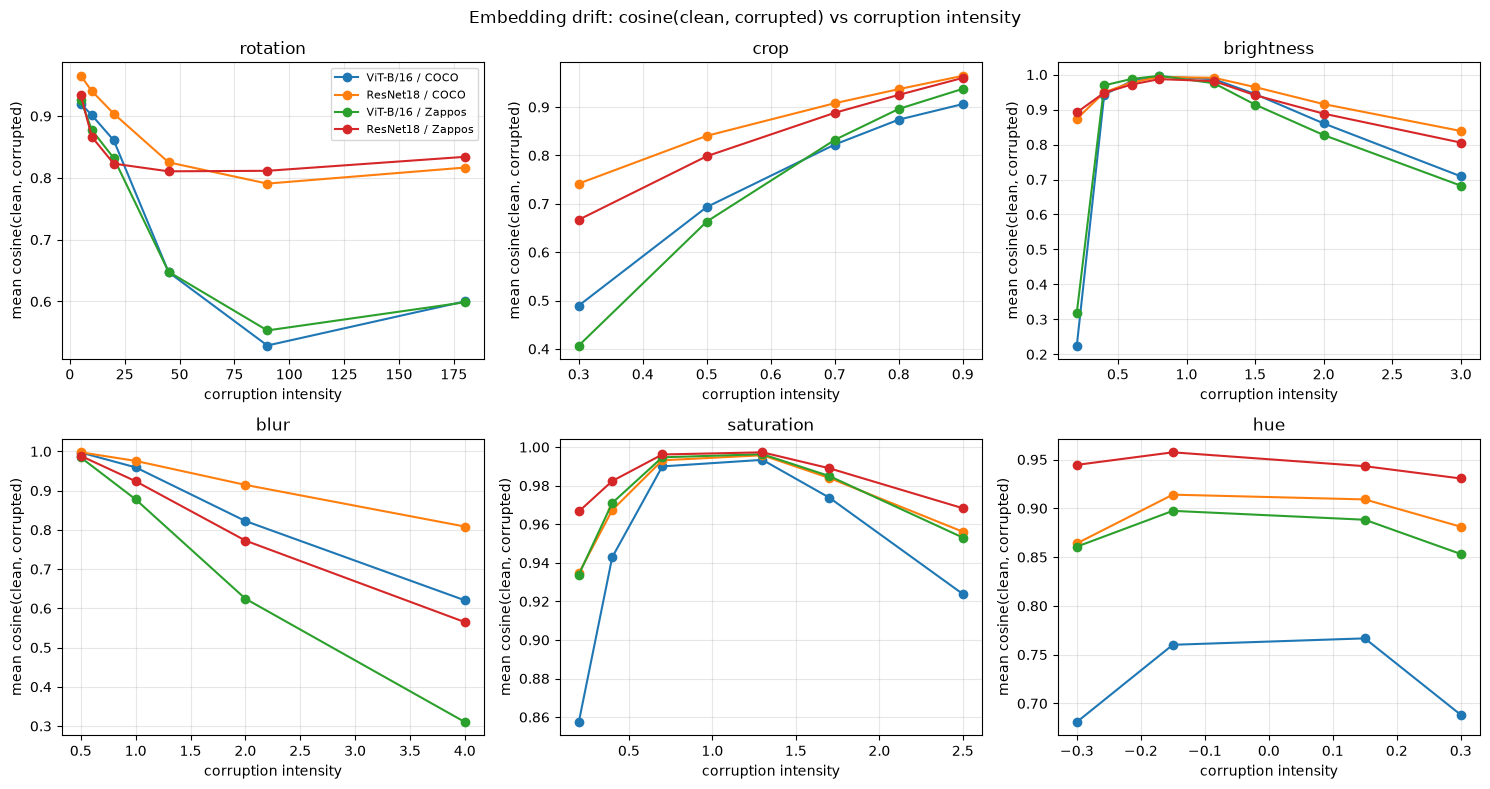

In [31]:
# The `corruption` frame was loaded in the setup cell. One panel per transform,
# one line per configuration, corrupted levels only.
if corruption is None:
    print("Embedding drift skipped: no corruption results. Run pipeline/corruption.py first.")
else:
    configs = [k for k in meta.index if (corruption["config"] == k).any()]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, spec in zip(axes.ravel(), TRANSFORMS):
        for k in configs:
            rows = (corruption[(corruption["config"] == k)
                               & (corruption["transform"] == spec["name"])]
                    .assign(level=lambda d: d["level"].astype(float))
                    .sort_values("level"))
            ax.plot(rows["level"], rows["cosine_mean"], marker="o",
                    color=CONFIG_COLORS[k], label=meta.loc[k, "label"])
        ax.set_title(spec["name"])
        ax.set_xlabel("corruption intensity")
        ax.set_ylabel("mean cosine(clean, corrupted)")
        ax.grid(alpha=0.3)
    axes[0][0].legend(fontsize=8)
    fig.suptitle("Embedding drift: cosine(clean, corrupted) vs corruption intensity")
    fig.tight_layout()
    save_figure(fig, "corruption_exact_cosine")
    plt.show()

### Corruption robustness: Recall@10

Recall@10 of the corrupted query searched with **exact search**, against the
clean query's exact neighbours - the model-only baseline. It isolates the
embedding model's response to corruption: whatever recall it loses cannot be
recovered by any index choice.

saved media/corruption_exact_recall_at_10.png


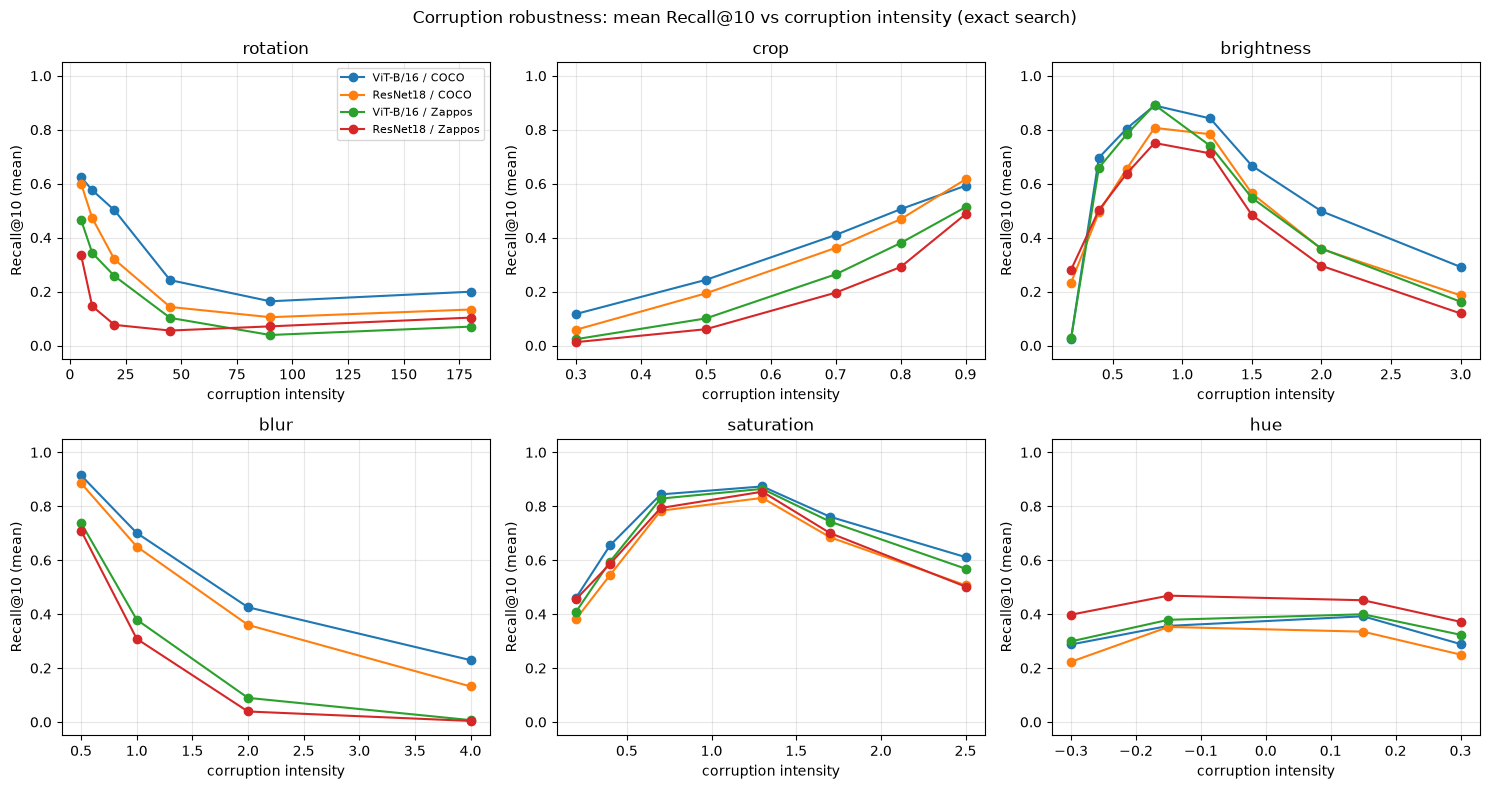

In [32]:
# Same format as the embedding-drift figure, now for exact-search Recall@10
# (the `corruption` frame was loaded in the setup cell).
if corruption is None:
    print("Exact-search Recall@10 skipped: no corruption results. Run pipeline/corruption.py first.")
else:
    configs = [k for k in meta.index if (corruption["config"] == k).any()]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, spec in zip(axes.ravel(), TRANSFORMS):
        for k in configs:
            rows = (corruption[(corruption["config"] == k)
                               & (corruption["transform"] == spec["name"])]
                    .assign(level=lambda d: d["level"].astype(float))
                    .sort_values("level"))
            ax.plot(rows["level"], rows["recall_at_10_mean"], marker="o",
                    color=CONFIG_COLORS[k], label=meta.loc[k, "label"])
        ax.set_title(spec["name"])
        ax.set_xlabel("corruption intensity")
        ax.set_ylabel("Recall@10 (mean)")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)
    axes[0][0].legend(fontsize=8)
    fig.suptitle("Corruption robustness: mean Recall@10 vs corruption intensity (exact search)")
    fig.tight_layout()
    save_figure(fig, "corruption_exact_recall_at_10")
    plt.show()

### ANN index view (IVF-Flat and HNSW)

The same corrupted queries, now searched with the ANN indexes. The gap
between an End-to-End curve and the exact-search Recall@10 figure above is
the extra loss the index itself adds.

saved media/corruption_ivfflat_fidelity_recall_at_10.png


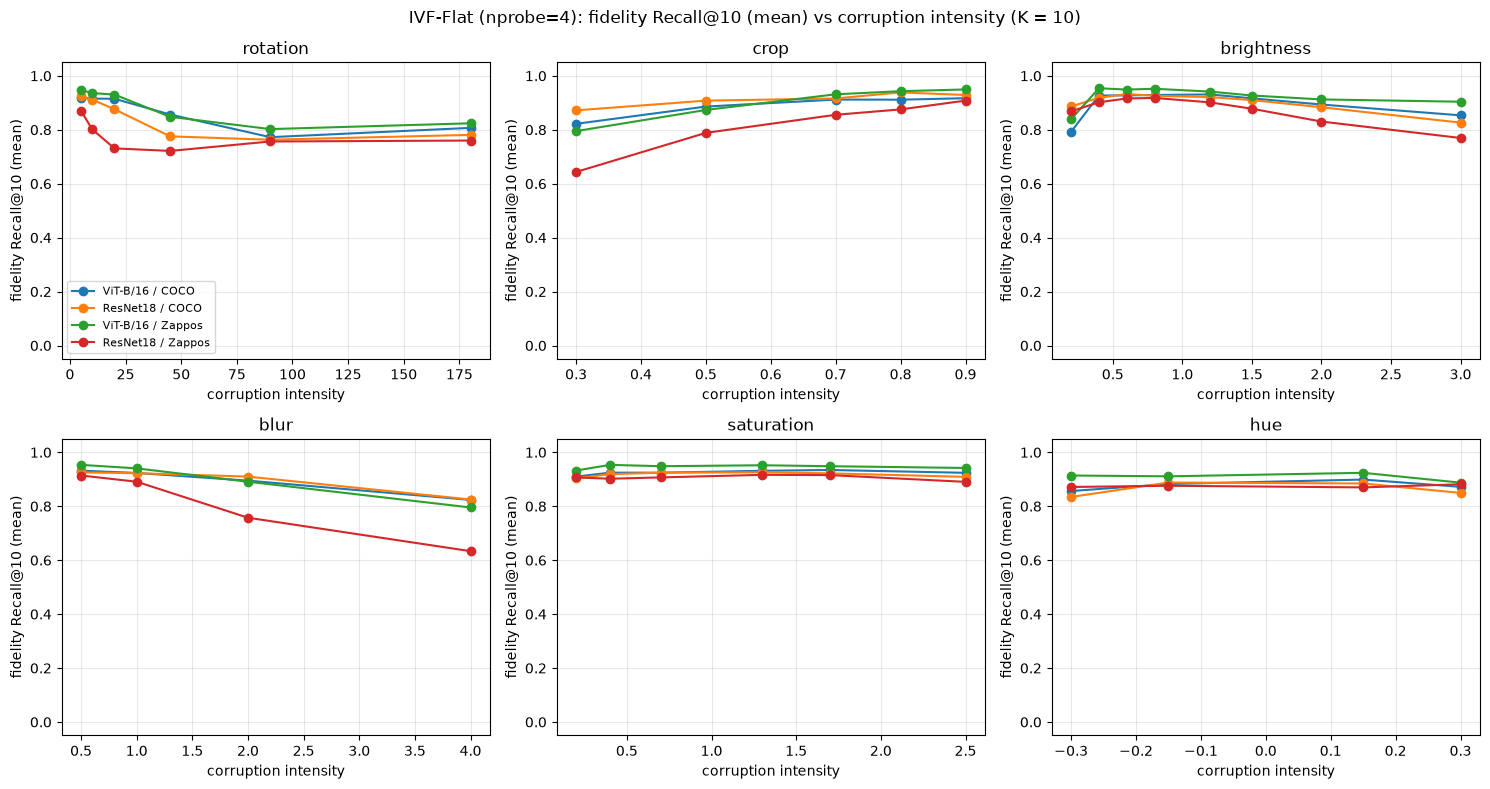

saved media/corruption_hnsw_fidelity_recall_at_10.png


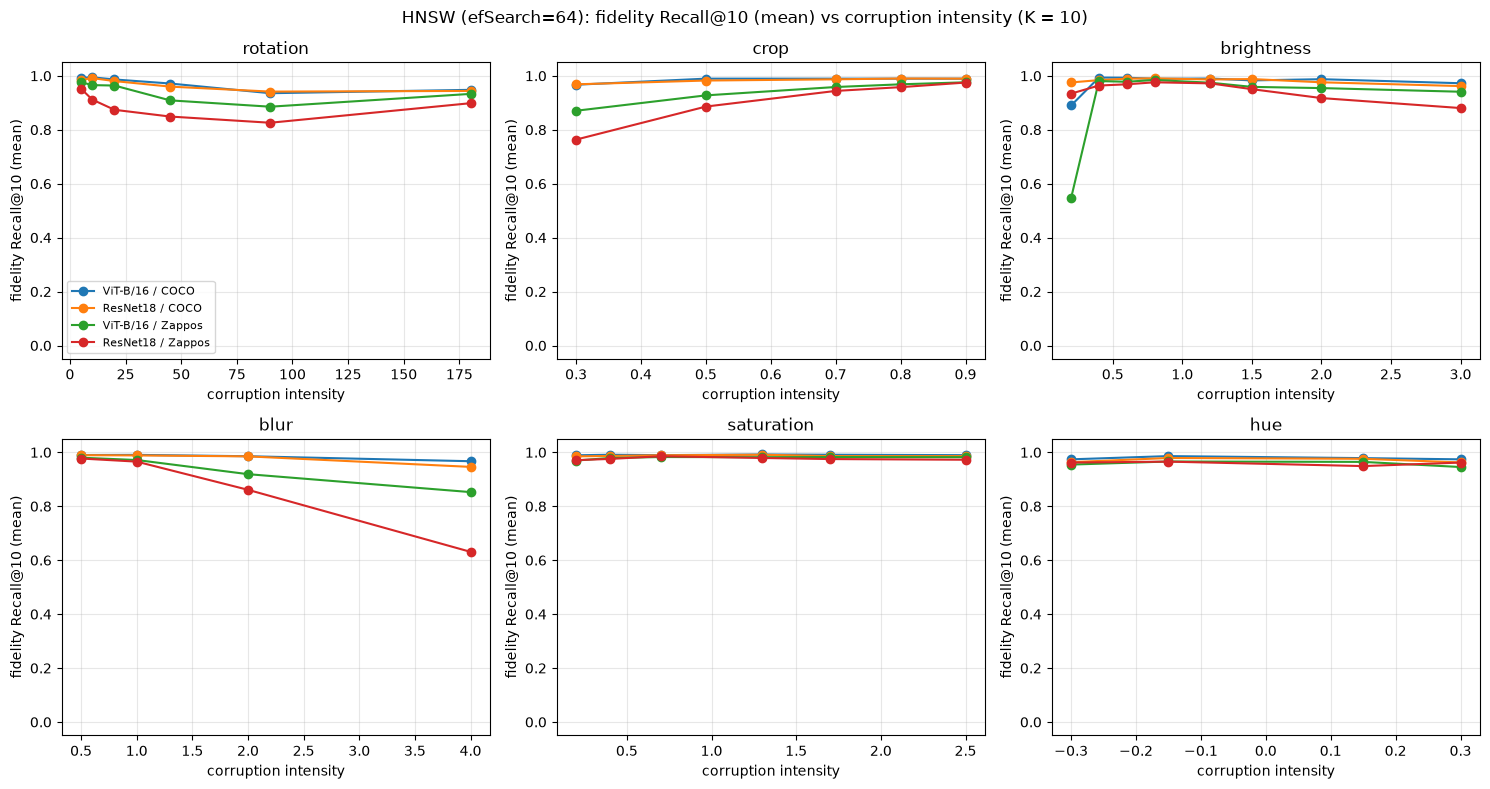

In [33]:
if ir_summary is not None:
    def corruption_curves(algorithm, column, ylabel, file_stem):
        """Exact-search figure format, one figure per index: one panel
        per transform, all four configurations as lines (colour = configuration)."""
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        for ax, spec in zip(axes.ravel(), TRANSFORMS):
            transform = spec["name"]
            for k in IR_KEYS:
                sub = (ir_summary[(ir_summary["config"] == k)
                                  & (ir_summary["algorithm"] == algorithm)
                                  & (ir_summary["transform"] == transform)]
                       .sort_values("order"))
                ax.plot(sub["level"].astype(float), sub[column], marker="o",
                        color=CONFIG_COLORS[k], label=meta.loc[k, "label"])
            ax.set_title(transform)
            ax.set_xlabel("corruption intensity")
            ax.set_ylabel(ylabel)
            ax.set_ylim(-0.05, 1.05)
            ax.grid(alpha=0.3)
        axes[0][0].legend(fontsize=8)
        setting = ir_summary[ir_summary["algorithm"] == algorithm]["setting"].iloc[0]
        fig.suptitle(f"{algorithm} ({setting}): {ylabel} vs corruption intensity (K = {K_SHOW})")
        fig.tight_layout()
        save_figure(fig, file_stem)
        plt.show()

    for algorithm, stem in (("IVF-Flat", "ivfflat"), ("HNSW", "hnsw")):
        corruption_curves(algorithm, f"fidelity_recall_at_{K_SHOW}_mean",
                          f"fidelity Recall@{K_SHOW} (mean)",
                          f"corruption_{stem}_fidelity_recall_at_{K_SHOW}")

saved media/corruption_ivfflat_end_to_end_recall_at_10.png


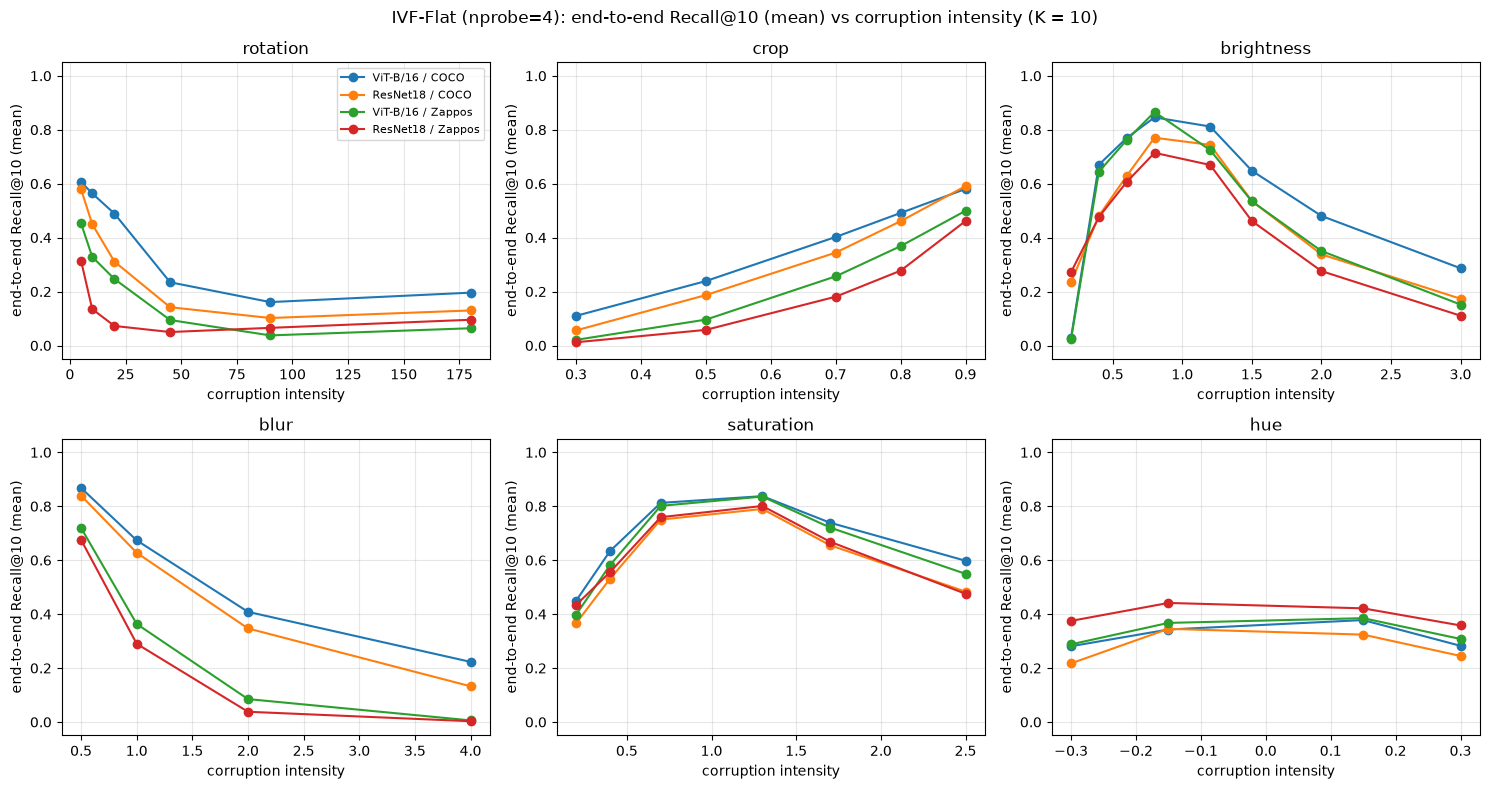

saved media/corruption_hnsw_end_to_end_recall_at_10.png


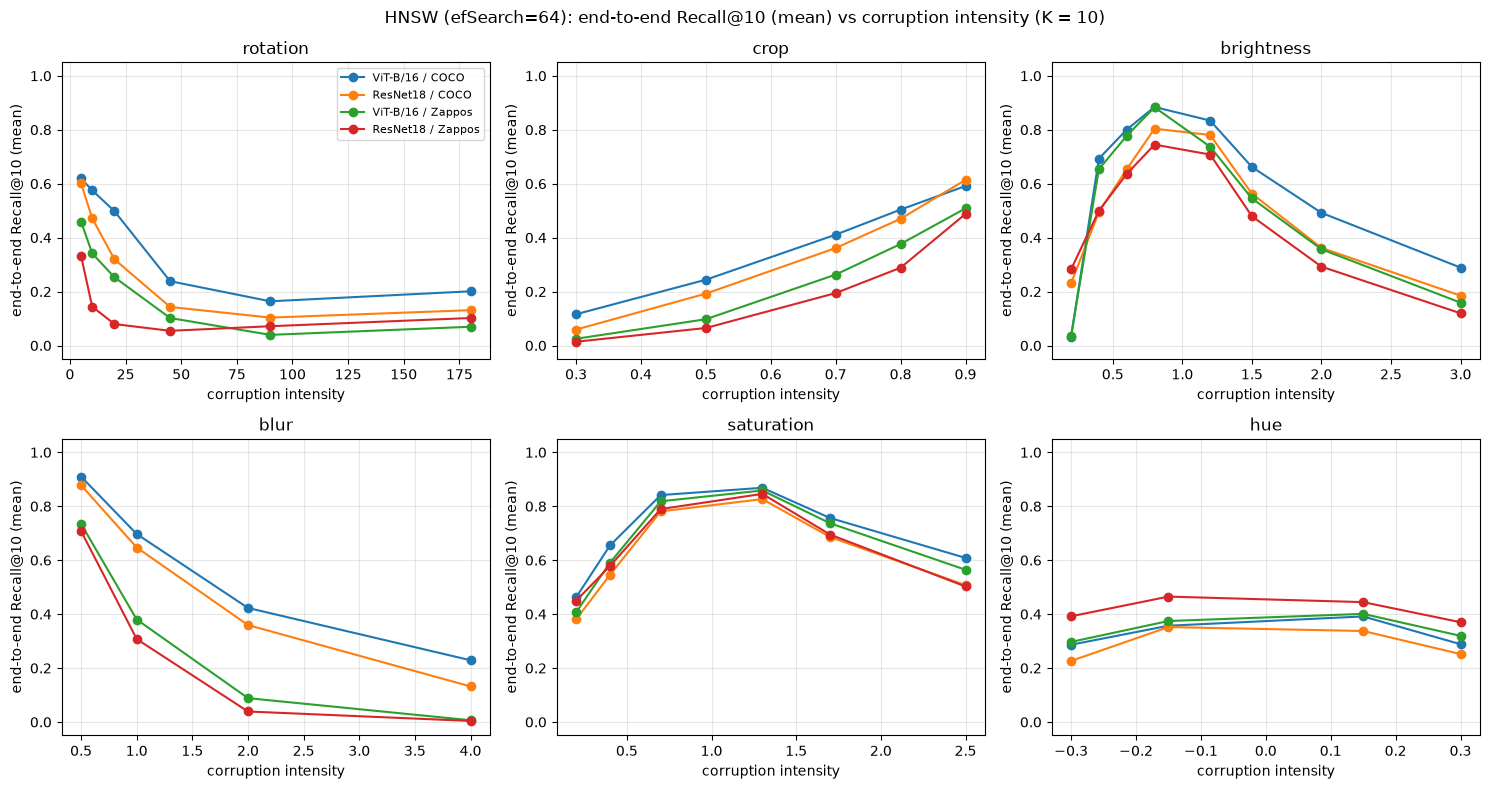

In [34]:
if ir_summary is not None:
    for algorithm, stem in (("IVF-Flat", "ivfflat"), ("HNSW", "hnsw")):
        corruption_curves(algorithm, f"end_to_end_recall_at_{K_SHOW}_mean",
                          f"end-to-end Recall@{K_SHOW} (mean)",
                          f"corruption_{stem}_end_to_end_recall_at_{K_SHOW}")

saved media/corruption_ivfflat_stability_recall_at_10.png


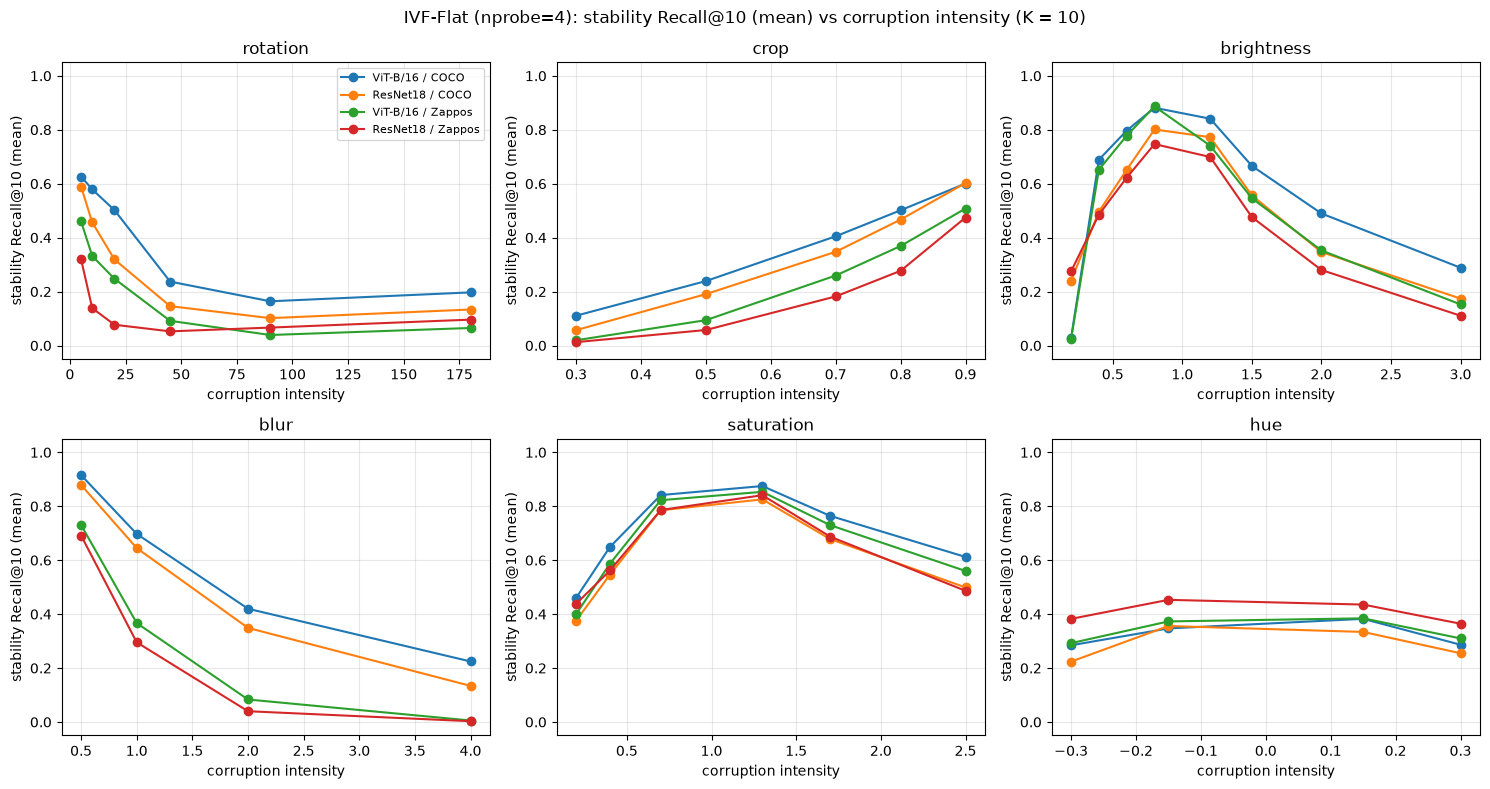

saved media/corruption_hnsw_stability_recall_at_10.png


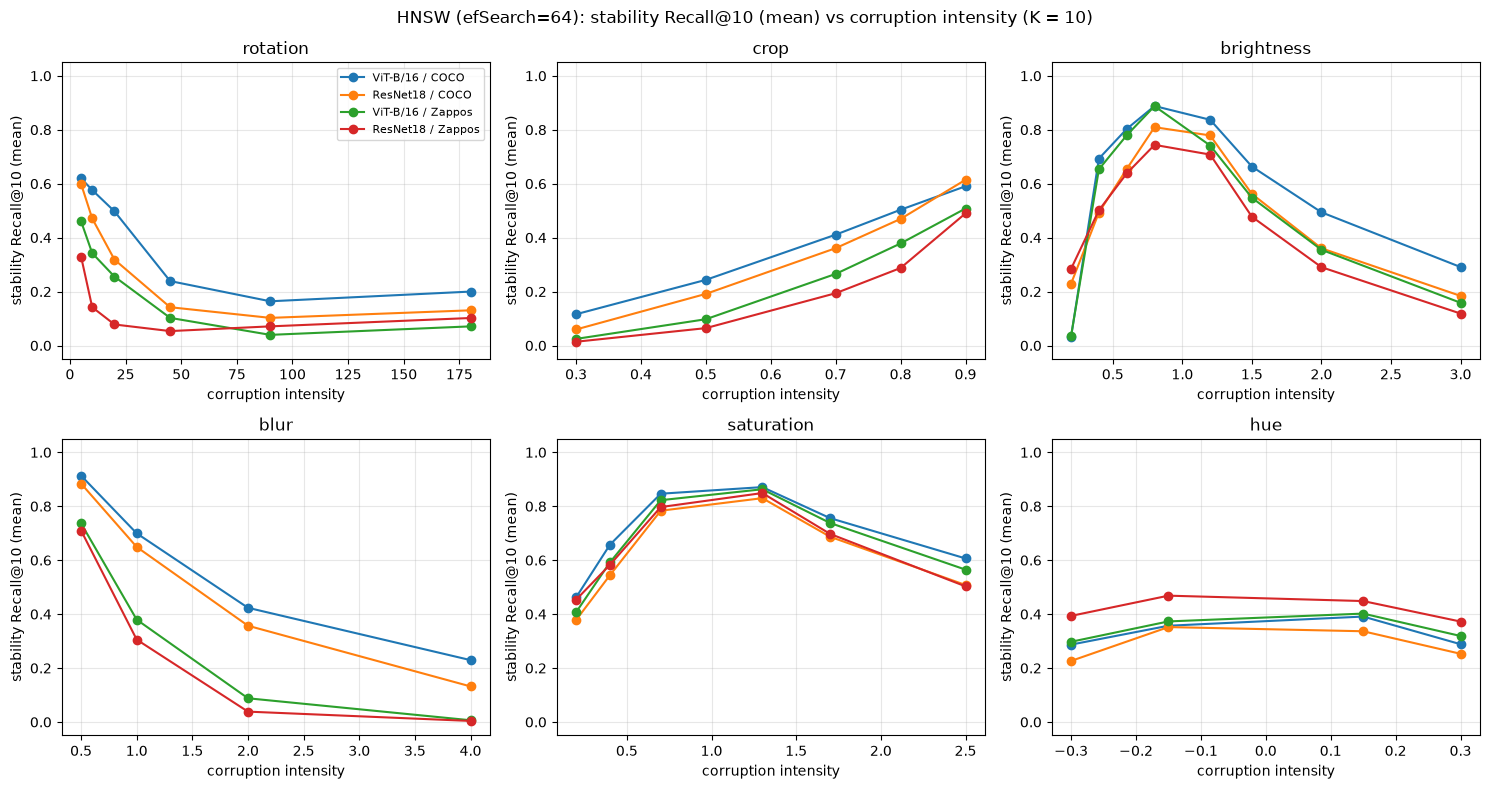

In [35]:
if ir_summary is not None:
    for algorithm, stem in (("IVF-Flat", "ivfflat"), ("HNSW", "hnsw")):
        corruption_curves(algorithm, f"stability_recall_at_{K_SHOW}_mean",
                          f"stability Recall@{K_SHOW} (mean)",
                          f"corruption_{stem}_stability_recall_at_{K_SHOW}")